# State-space phase estimation

This notebook applies an independent Python implementation of the stochastic-oscillator model introduced by [Matsuda and Komaki (2017)](https://doi.org/10.1162/NECO_a_00916) and adapted for real-time state-space phase estimation (SSPE) by [Wodeyar et al. (2021)](https://elifesciences.org/articles/68803).

Each latent component is a damped, noise-driven planar oscillator,

$$x_{j,k}=a_jR(2\pi f_j/F_s)x_{j,k-1}+u_{j,k},$$

and the observation is the sum of the components' real coordinates plus measurement noise. The real and imaginary coordinates form an analytic signal whose phase is $\arg(x_1+i x_2)$. Parameters are estimated by expectation-maximization (EM), using Kalman filtering and Rauch--Tung--Striebel smoothing in each E-step.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from matplotlib.ticker import FuncFormatter, MultipleLocator

import SSPE

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
rng = np.random.default_rng(12345)
cm = 1 / 2.54  # centimeters to inches

## Hippocampal data

Use the sixth EEG channel and the same 4,000-point, stride-4 interval used by the Bayesian Hippocampal example.

In [5]:
n_channels = 31
raw_sampling_frequency = 1250.0  # Hz
stride = 4
sampling_frequency = raw_sampling_frequency / stride

data_path = Path('../Hippocampal/data/ec013.527.eeg')
eeg = np.fromfile(data_path, dtype=np.int16).reshape(-1, n_channels)

start = 10_000
n_samples = 4_000
stop = start + stride * n_samples
signal = eeg[start:stop:stride, 5].astype(float)
signal_centered = signal - signal.mean()
time = np.arange(n_samples) / sampling_frequency

print(f'{n_samples} samples over {time[-1]:.3f} s')
print(f'Sampling frequency: {sampling_frequency:g} Hz')

4000 samples over 12.797 s
Sampling frequency: 312.5 Hz


## Spectral initialization and EM fit

The implementation supports any number of oscillators. Here, three components are initialized from the strongest periodogram peaks in 0.5–4 Hz, 4–12 Hz, and 12–30 Hz. These are starting values only: EM estimates each frequency, damping factor, process variance, and the shared observation variance.

In [6]:
fft_values = np.fft.rfft(signal_centered)
frequencies = np.fft.rfftfreq(n_samples, d=1 / sampling_frequency)
power = np.abs(fft_values) ** 2
peak_indices, _ = find_peaks(power)

initialization_bands = [(0.5, 4.0), (4.0, 12.0), (12.0, 30.0)]
initial_frequencies = []
for lower, upper in initialization_bands:
    candidates = peak_indices[
        (frequencies[peak_indices] >= lower)
        & (frequencies[peak_indices] <= upper)
    ]
    if candidates.size == 0:
        raise RuntimeError(f'No spectral peak found in {lower:g}–{upper:g} Hz.')
    initial_frequencies.append(frequencies[candidates[np.argmax(power[candidates])]])

initial_frequencies = np.asarray(initial_frequencies)
print('Initial frequencies (Hz):', initial_frequencies)

Initial frequencies (Hz): [ 2.265625  8.359375 16.796875]


In [7]:
fit = SSPE.fit_sspe(
    signal_centered,
    sampling_frequency,
    initial_frequencies,
    initial_damping=0.99,
    max_iterations=600,
    frequency_tolerance=1e-3,
)

print(f"Converged: {fit['converged']} after {fit['n_iterations']} EM updates")
print('Fitted frequencies (Hz):', fit['frequencies'])
print('Fitted damping factors: ', fit['damping'])
print('Process variances:       ', fit['process_variances'])
print('Observation variance:    ', fit['observation_variance'])

Converged: True after 464 EM updates
Fitted frequencies (Hz): [ 3.29064017  8.25677155 15.46795052]
Fitted damping factors:  [0.94889342 0.99545443 0.83094722]
Process variances:        [ 4297.73387559  3289.57859103 32836.57542048]
Observation variance:     869.5966776542172


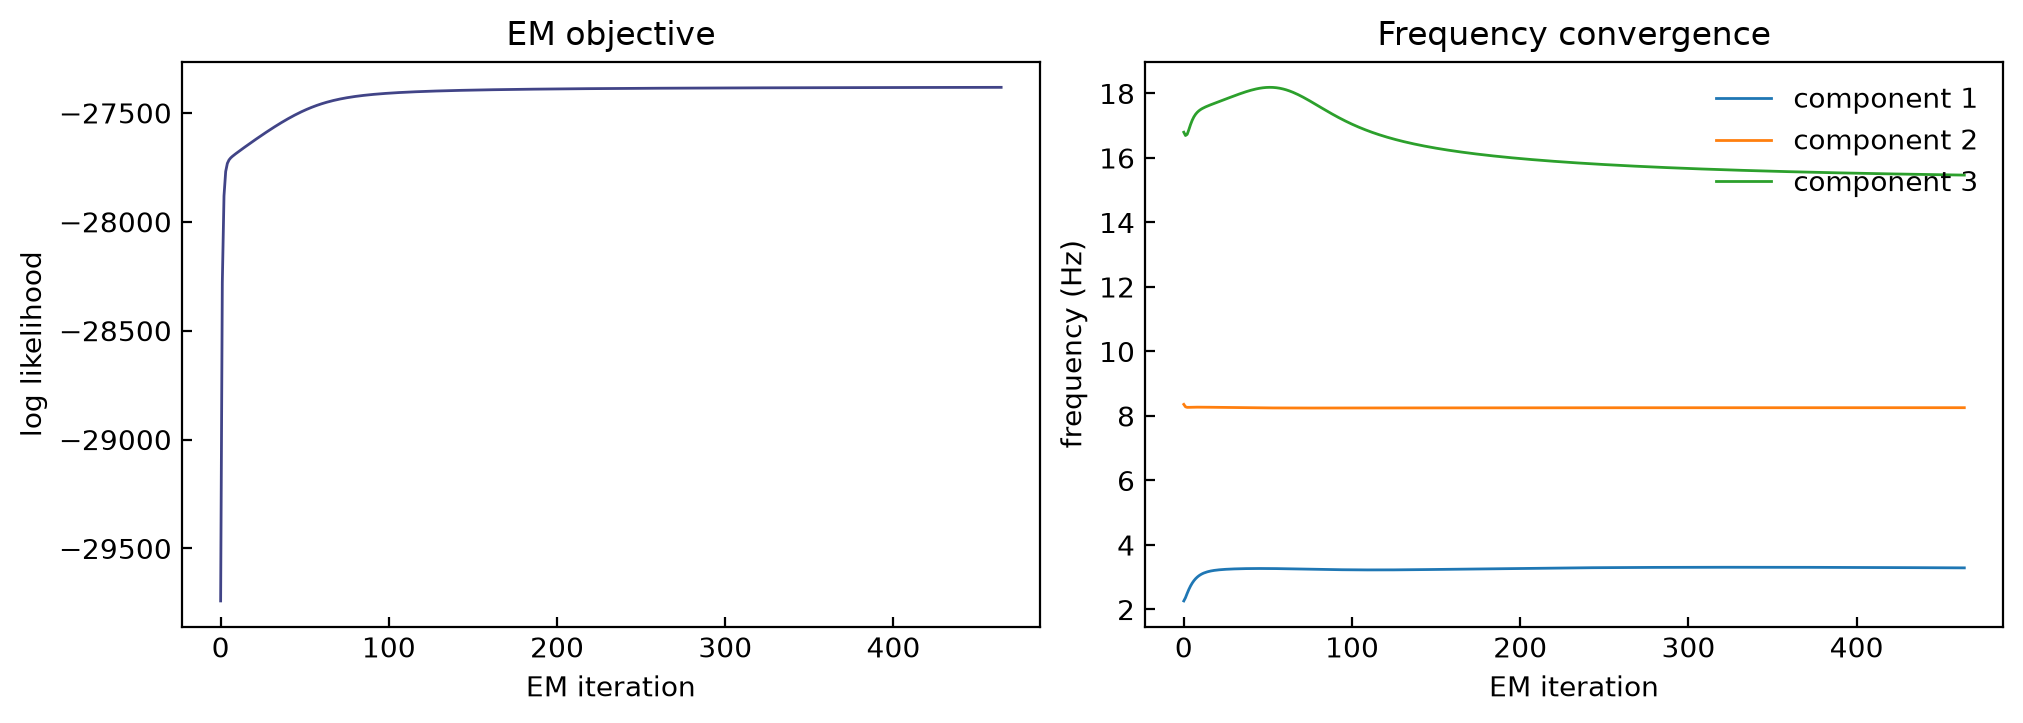

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot(fit['likelihood_history'], color=cmap(0.2), lw=1)
axes[0].set(xlabel='EM iteration', ylabel='log likelihood', title='EM objective')

for component in range(fit['frequency_history'].shape[1]):
    axes[1].plot(
        fit['frequency_history'][:, component],
        lw=1,
        label=f'component {component + 1}',
    )
axes[1].set(xlabel='EM iteration', ylabel='frequency (Hz)', title='Frequency convergence')
axes[1].legend(frameon=False)
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

## Visualization

### Signal Reconstruction

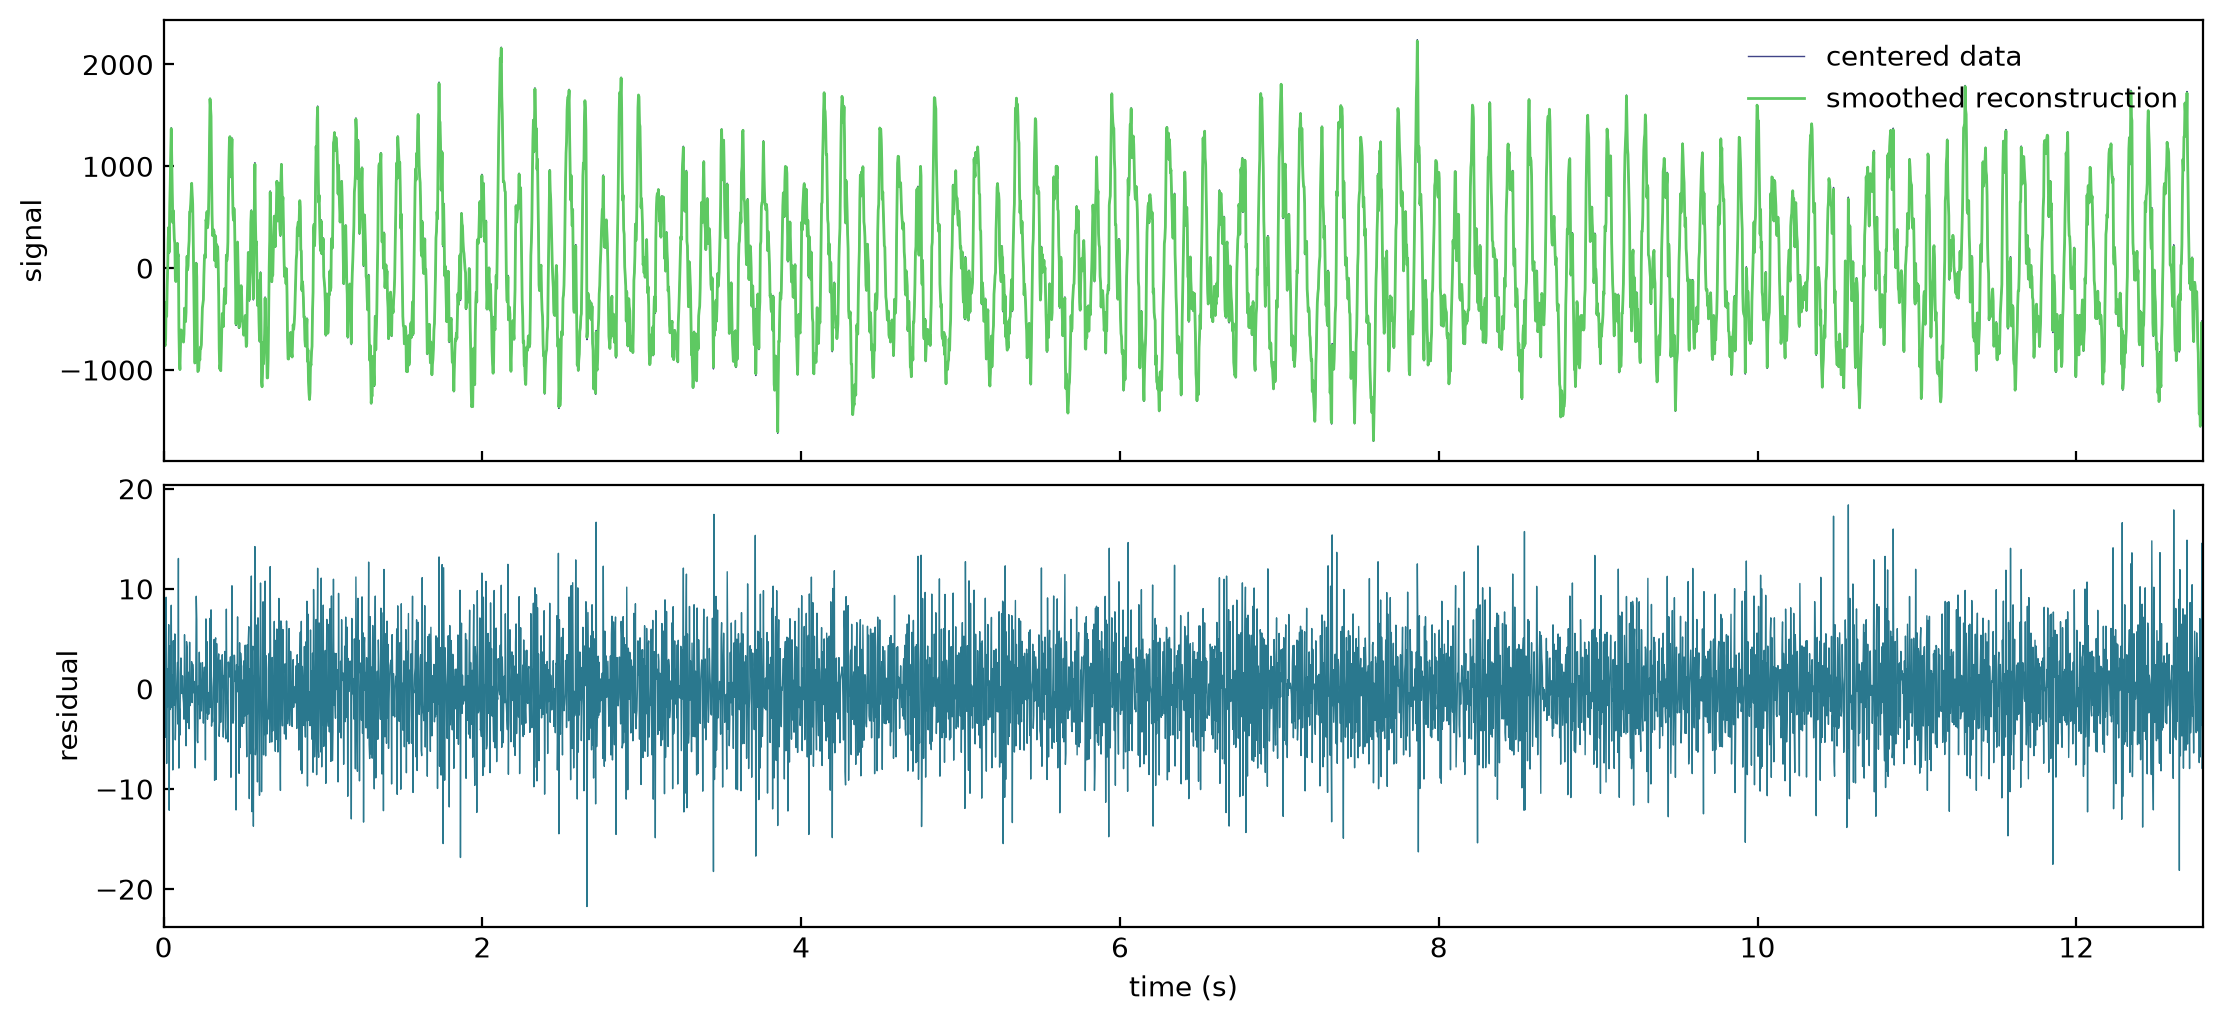

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
axes[0].plot(time, signal_centered, color=cmap(0.2), lw=0.5, label='centered data')
axes[0].plot(
    time,
    fit['smoothed_reconstruction'],
    color=cmap(0.75),
    lw=1,
    label='smoothed reconstruction',
)
axes[0].set_ylabel('signal')
axes[0].legend(frameon=False)

residual = signal_centered - fit['smoothed_reconstruction']
axes[1].plot(time, residual, color=cmap(0.4), lw=0.5)
axes[1].set(xlabel='time (s)', ylabel='residual', xlim=(time[0], time[-1]))
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

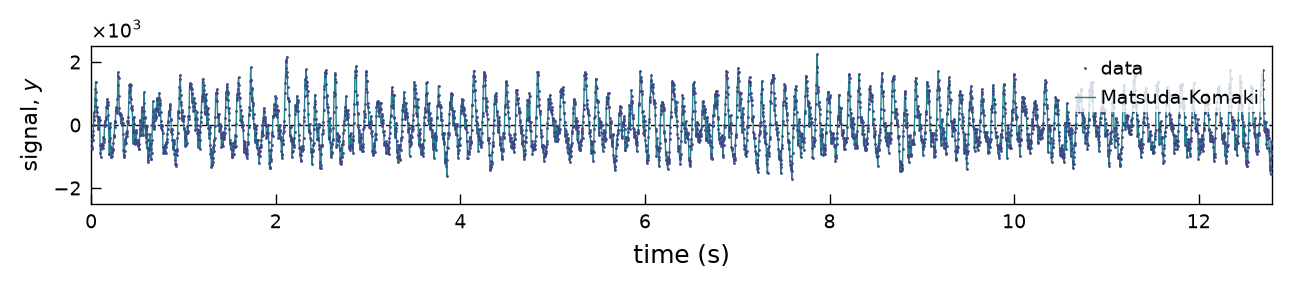

Saved reconstruction figure to plots/SSPE_reconstruction.pdf


In [11]:
# Exact axis dimensions
ax_w = 15.0 * cm
ax_h = 2.0 * cm

# Figure margins
left = 1.5 * cm
right = 0.3 * cm
bottom = 1.2 * cm
top = 0.4 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))
ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h,
])

ax.plot(
    time,
    signal_centered,
    '.',
    color=cmap(0.2),
    ms=2,
    mew=0,
    ls='none',
    label='data',
    zorder=10,
)
ax.plot(
    time,
    fit['smoothed_reconstruction'],
    color=cmap(0.45),
    lw=0.5,
    label='Matsuda-Komaki',
)
ax.axhline(0, color='black', lw=0.5, ls='--', zorder=-10)

def reconstruction_thousands_formatter(value, position):
    text = f'{value / 1000:g}'
    return text.replace('-', '−')

ax.set_xlim(time[0], time[-1])
ax.set_ylim(-2500, 2500)
ax.set_yticks([-2000, 0, 2000])
ax.yaxis.set_major_formatter(reconstruction_thousands_formatter)
ax.set_xlabel('time (s)', fontsize=9)
ax.set_ylabel('signal, $y$', fontsize=8)
ax.tick_params(
    axis='both', which='major', labelsize=7, width=0.5, direction='in'
)
ax.tick_params(
    axis='both', which='minor', labelsize=7, width=0.5, direction='in'
)
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

legend = ax.legend(
    loc='upper right',
    fontsize=7,
    handlelength=1.0,
    handletextpad=0.3,
    borderpad=0.2,
    frameon=True,
    facecolor='white',
    edgecolor='none',
    framealpha=0.8,
)
legend.set_zorder(20)
ax.text(
    0.0,
    1.02,
    r'$\times 10^{3}$',
    transform=ax.transAxes,
    ha='left',
    va='bottom',
    fontsize=7,
)

reconstruction_path = Path('plots/SSPE_reconstruction.pdf')
fig.savefig(reconstruction_path)
plt.show()
print(f'Saved reconstruction figure to {reconstruction_path}')

### Signal Decomposition

#### Initial plot

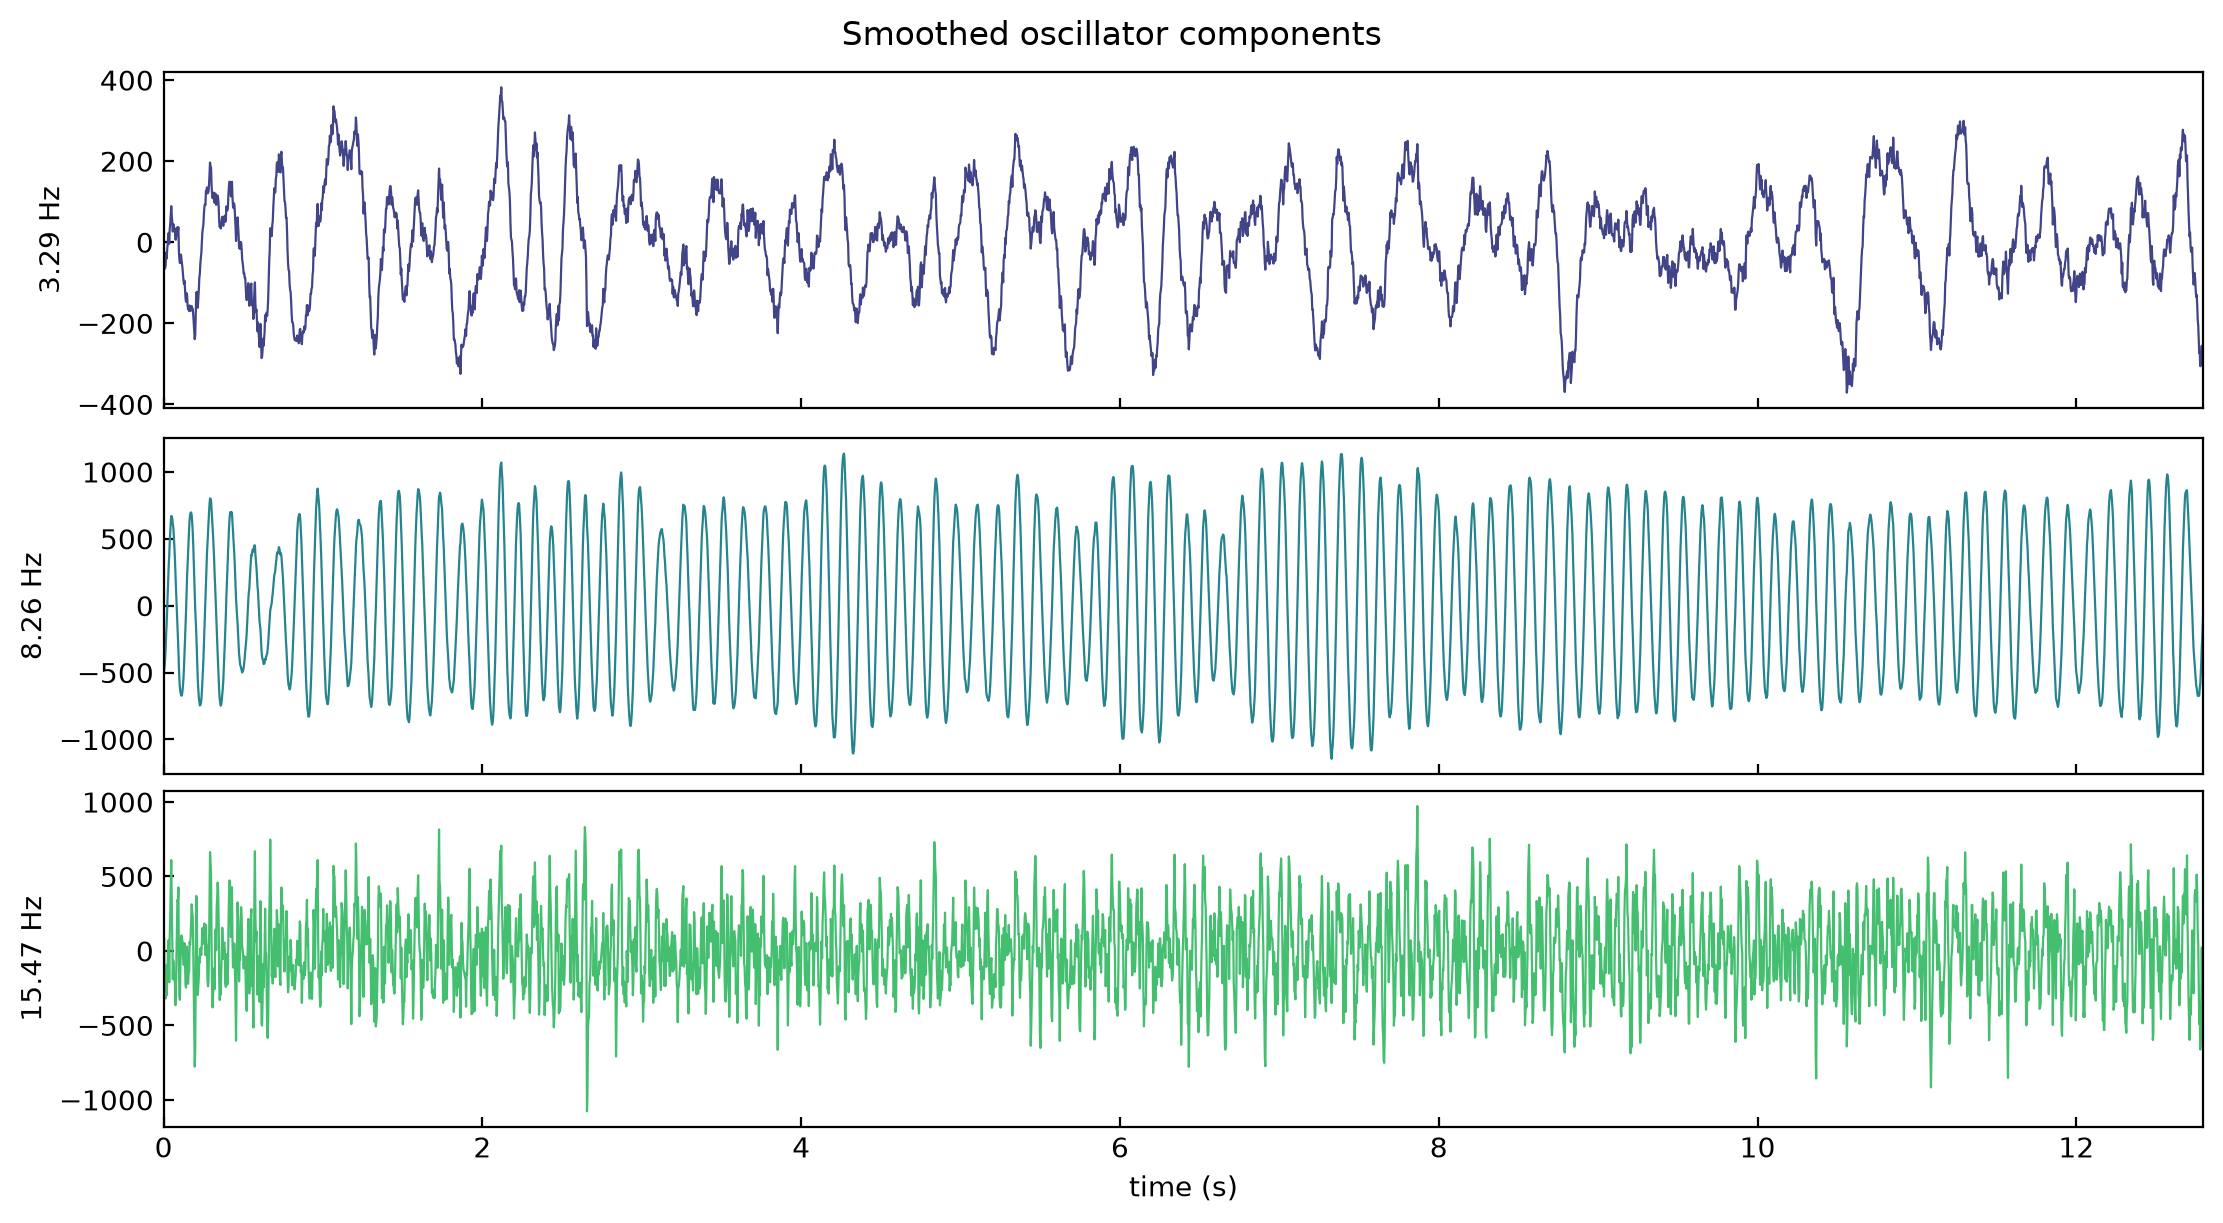

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
for component, ax in enumerate(axes):
    ax.plot(
        time,
        fit['smoothed_components'][:, component],
        color=cmap(0.2 + 0.25 * component),
        lw=0.8,
    )
    ax.set_ylabel(f"{fit['frequencies'][component]:.2f} Hz")
    ax.tick_params(direction='in')
axes[-1].set(xlabel='time (s)', xlim=(time[0], time[-1]))
fig.suptitle('Smoothed oscillator components')
plt.show()

#### Publication Plot

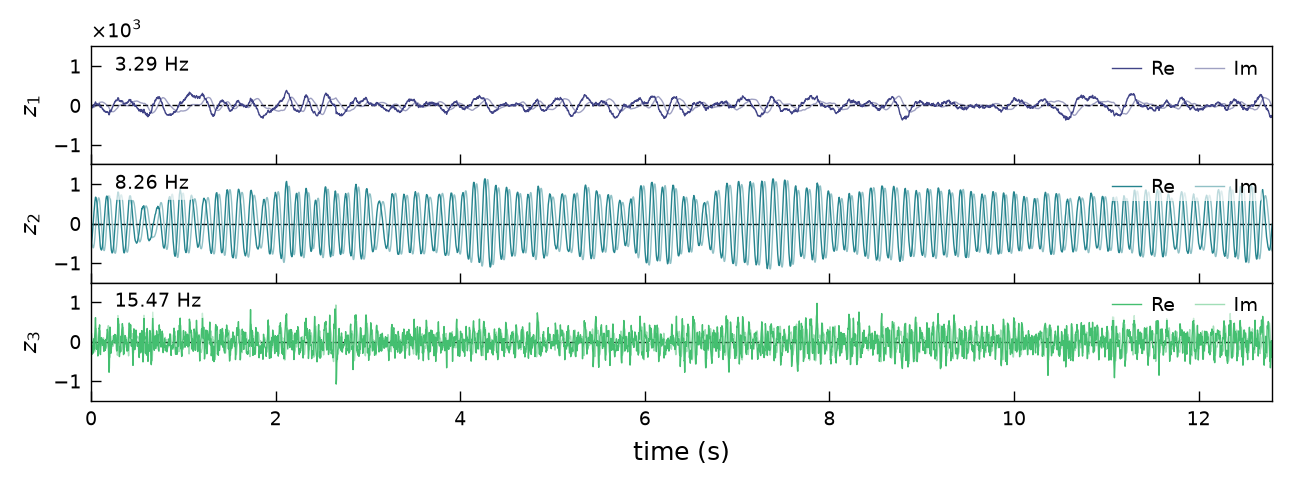

Saved trajectory figure to plots/SSPE_components.pdf


In [13]:
# Exact combined axis dimensions
ax_w = 15.0 * cm
total_ax_h = 4.5 * cm

# Figure margins
left = 1.5 * cm
right = 0.3 * cm
bottom = 1.2 * cm
top = 0.4 * cm

fig_w = left + ax_w + right
fig_h = bottom + total_ax_h + top

smoothed_mean = fit["smoother"]["smoothed_mean"]
components = smoothed_mean[:, ::2] + 1j * smoothed_mean[:, 1::2]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(fig_w, fig_h),
    sharex=True,
    sharey=True,
    gridspec_kw={"hspace": 0},
)

fig.subplots_adjust(
    left=left / fig_w,
    right=1 - right / fig_w,
    bottom=bottom / fig_h,
    top=1 - top / fig_h,
    hspace=0,
)

def thousands_formatter(value, position):
    text = f'{value / 1000:g}'
    return text.replace('-', '−')

# Display -1000, 0, 1000 as -1, 0, 1
# thousands_formatter = FuncFormatter(lambda value, position: f"{value / 1000:g}")

for component, ax in enumerate(axes):
    ax.plot(
        time,
        components[:, component].real,
        color=cmap(0.2 + 0.25 * component),
        lw=0.5,
        alpha=1,
        label="Re",
    )
    ax.plot(
        time,
        components[:, component].imag,
        color=cmap(0.2 + 0.25 * component),
        lw=0.5,
        alpha=0.5,
        label="Im",
    )
    ax.axhline(
        0,
        color='black',
        lw=0.5,
        ls='--',
        zorder=-10,
    )
    ax.text(
        0.02,
        0.75,
        rf"${fit['frequencies'][component]:.2f}\ \mathrm{{Hz}}$",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=7,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7, edgecolor="none")
    )

    ax.set_ylabel(
        rf"$z_{{{component + 1}}}$",
        fontsize=8,
    )
    ax.set_ylim(-1500, 1500)
    ax.set_yticks([-1000, 0, 1000])
    ax.yaxis.set_major_formatter(thousands_formatter)

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=7,
        width=0.5,
        direction="in",
    )
    ax.tick_params(
        axis="both",
        which="minor",
        labelsize=7,
        width=0.5,
        direction="in",
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)

    ax.legend(
        loc="upper right",
        ncol=2,
        fontsize=7,
        frameon=True,
        edgecolor="none",
        facecolor="white",
        handlelength=1.5,
        handletextpad=0.5,
        borderpad=0.2,
        framealpha=0.7,
        columnspacing=1.0,   # <--- reduce spacing between columns
    )

# Show the common scale factor above the top panel only
axes[0].text(
    0.0,
    1.03,
    r"$\times 10^{3}$",
    transform=axes[0].transAxes,
    ha="left",
    va="bottom",
    fontsize=7,
)

axes[-1].set_xlim(time[0], time[-1])
axes[-1].set_xlabel("time (s)", fontsize=9)

trajectory_path = Path('plots/SSPE_components.pdf')
fig.savefig(trajectory_path)
plt.show()
print(f'Saved trajectory figure to {trajectory_path}')

## Theta phase and uncertainty

The primary estimate is the acausal RTS-smoothed phase. The forward-filtered phase is also available in `fit['filtered_phase']` for causal applications. Phase uncertainty is evaluated in two ways: a local delta-method approximation and direct seeded sampling from each smoothed bivariate Gaussian state. Monte Carlo intervals remain meaningful when the phase distribution becomes non-Gaussian at low amplitude.

In [14]:
theta_candidates = np.flatnonzero(
    (fit['frequencies'] >= 4.0) & (fit['frequencies'] <= 12.0)
)
if theta_candidates.size != 1:
    raise RuntimeError('Expected exactly one fitted component in the 4–12 Hz theta band.')
theta_component = theta_candidates.item()
theta_frequency_sspe = fit['frequencies'][theta_component]

delta_uncertainty = SSPE.phase_uncertainty_delta(
    fit['smoother']['smoothed_mean'],
    fit['smoother']['smoothed_covariance'],
    theta_component,
)
mc_uncertainty = SSPE.phase_uncertainty_monte_carlo(
    fit['smoother']['smoothed_mean'],
    fit['smoother']['smoothed_covariance'],
    theta_component,
    n_samples=2000,
    quantiles=(0.025, 0.25, 0.75, 0.975),
    rng=rng,
)
print(f'SSPE theta frequency: {theta_frequency_sspe:.6f} Hz')

SSPE theta frequency: 8.256772 Hz


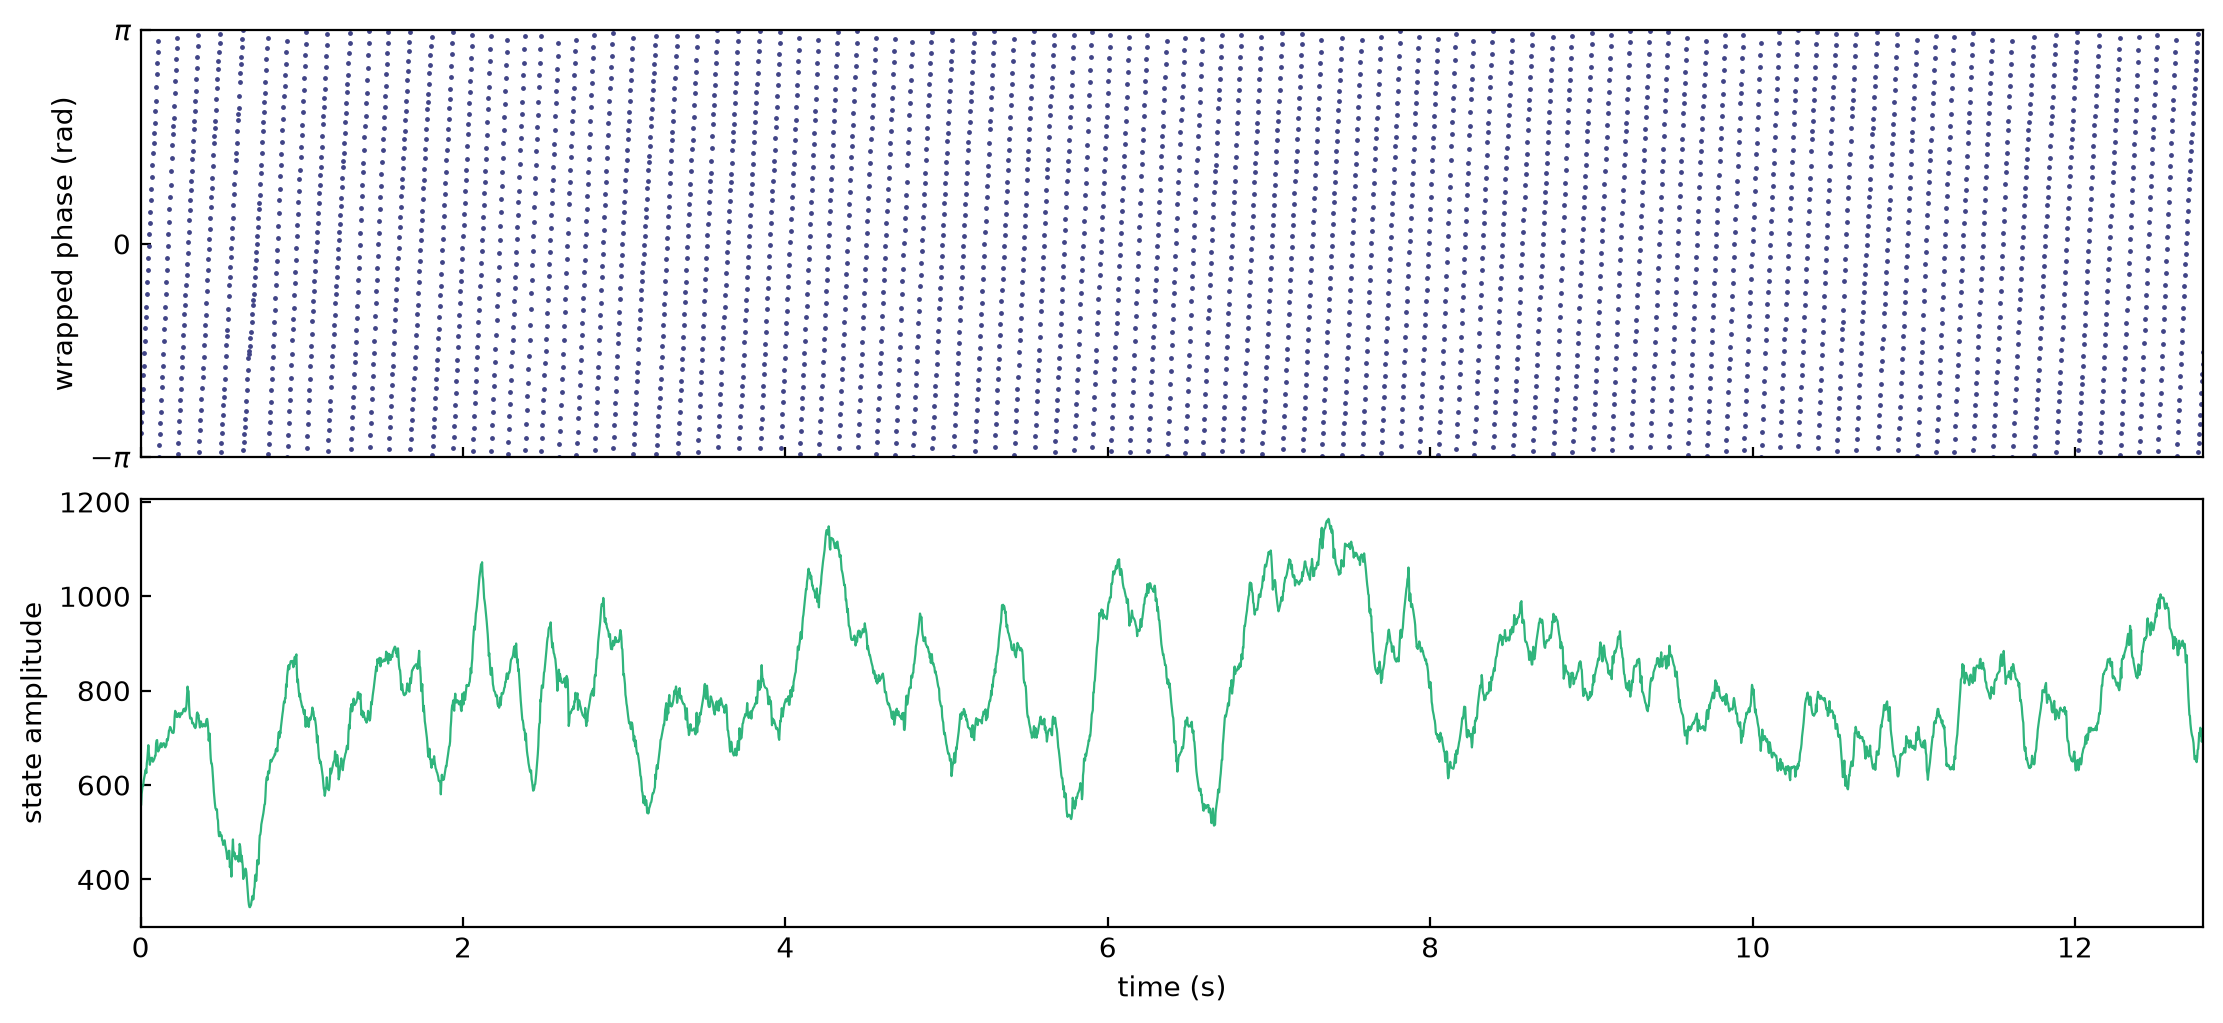

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
axes[0].plot(time, mc_uncertainty['phase_wrapped'], '.', color=cmap(0.2), ms=1.5)
axes[0].set(
    ylabel='wrapped phase (rad)',
    ylim=(-np.pi, np.pi),
    yticks=(-np.pi, 0, np.pi),
    yticklabels=(r'$-\pi$', '0', r'$\pi$'),
)
axes[1].plot(time, mc_uncertainty['amplitude'], color=cmap(0.65), lw=0.8)
axes[1].set(
    xlabel='time (s)',
    ylabel='state amplitude',
    xlim=(time[0], time[-1]),
)
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

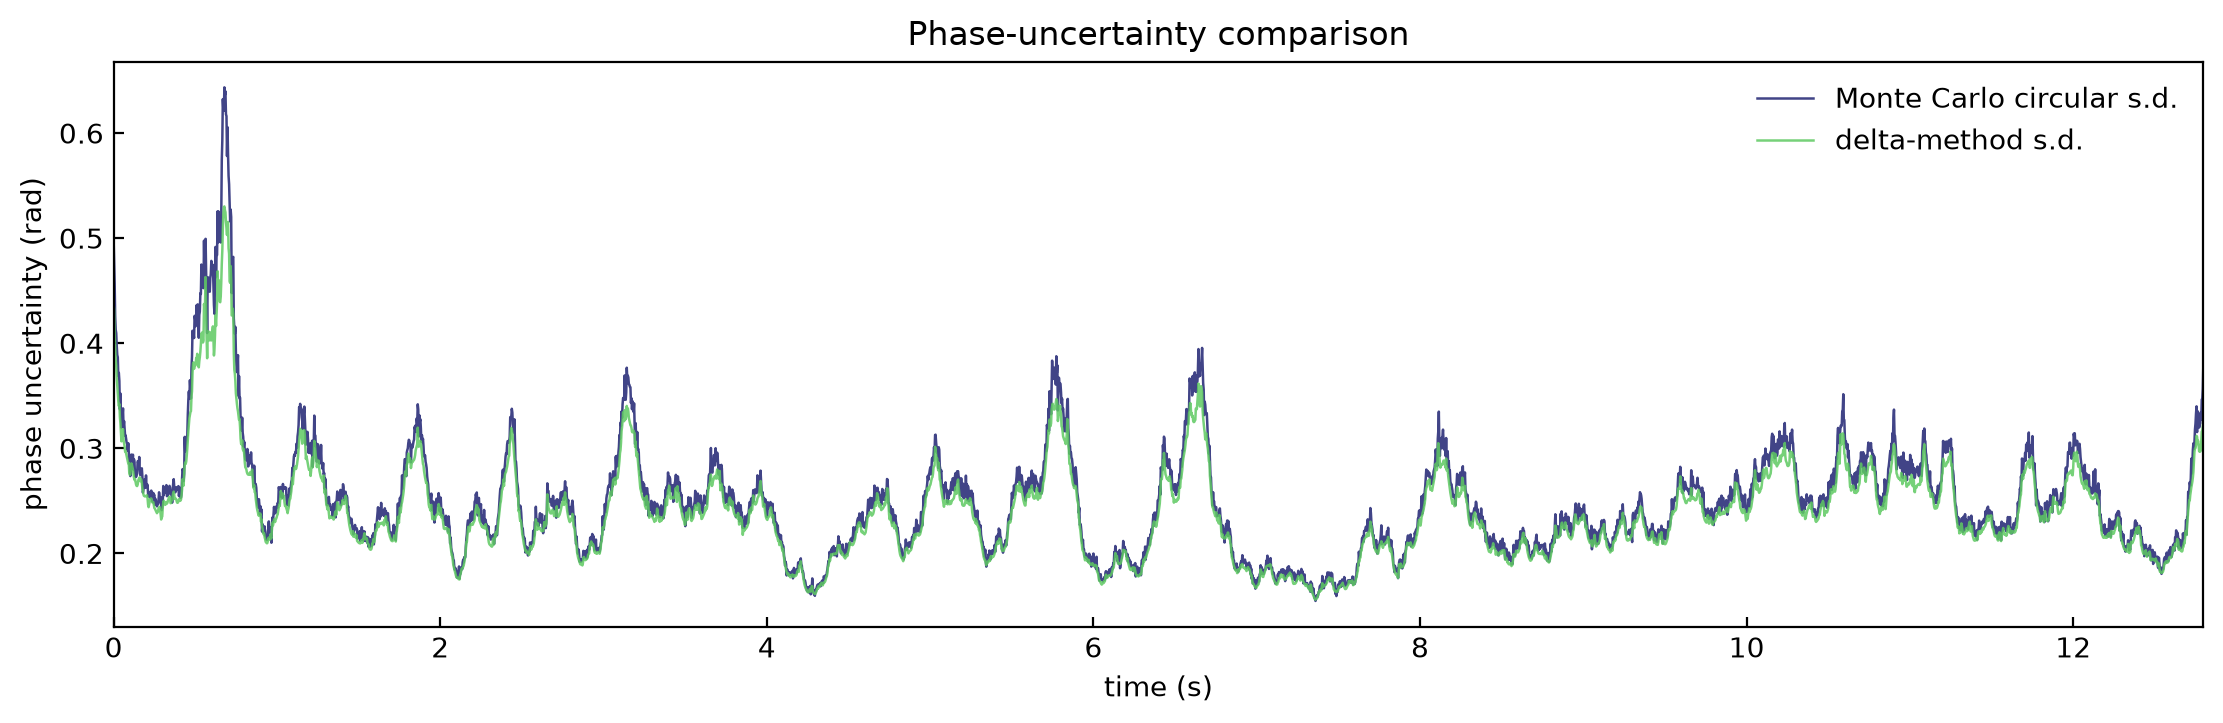

In [16]:
fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.plot(
    time,
    mc_uncertainty['circular_std'],
    color=cmap(0.2),
    lw=0.9,
    label='Monte Carlo circular s.d.',
)
ax.plot(
    time,
    delta_uncertainty['phase_std'],
    color=cmap(0.75),
    lw=0.9,
    alpha=0.85,
    label='delta-method s.d.',
)
ax.set(
    xlabel='time (s)',
    ylabel='phase uncertainty (rad)',
    title='Phase-uncertainty comparison',
    xlim=(time[0], time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

## Comparison with our method

The state-space observation uses the real oscillator coordinate, so phase zero is the positive cosine direction. This is the same first-harmonic gauge used by the Bayesian waveform. Consequently, only the equivalent integer-$2\pi$ unwrapping branch is selected; no continuous phase offset is fitted.

In [17]:
omega_sspe = 2 * np.pi * theta_frequency_sspe
relative_phase_sspe = mc_uncertainty['phase_unwrapped'] - omega_sspe * time
relative_quantiles_sspe = (
    mc_uncertainty['phase_quantiles'] - omega_sspe * time[:, None]
)

with np.load('../Hippocampal/data/phi_inf_data_good.npz') as inference_data:
    inference_time = inference_data['tk']
    inferred_phase_mean = inference_data['phi_inf_mean']
    inferred_phase_lo = inference_data['phi_inf_lo']
    inferred_phase_hi = inference_data['phi_inf_hi']

if not np.allclose(time, inference_time):
    raise RuntimeError('SSPE and Bayesian time grids do not match.')

branch_shift = 2 * np.pi * np.round(
    (inferred_phase_mean[0] - relative_phase_sspe[0]) / (2 * np.pi)
)
relative_phase_sspe += branch_shift
relative_quantiles_sspe += branch_shift

sspe_iqr_lo = relative_quantiles_sspe[:, 1]
sspe_iqr_hi = relative_quantiles_sspe[:, 2]

In [18]:
with np.load('../Hippocampal/data/parameter_estimates_good.npz') as parameter_data:
    map_estimate = parameter_data['map_estimate']
    parameter_names = parameter_data['parameter_names']
omega_map = map_estimate[np.flatnonzero(parameter_names == 'omega').item()]
map_frequency = omega_map / (2 * np.pi)

fft_index = 1 + np.argmax(power[1:])
fft_peak_frequency = frequencies[fft_index]

print(f'SSPE fitted frequency: {theta_frequency_sspe:.6f} Hz')
print(f'Bayesian MAP frequency: {map_frequency:.6f} Hz')
print(f'FFT peak frequency:     {fft_peak_frequency:.6f} Hz')
print(f'Branch shift:           {branch_shift / (2 * np.pi):.0f} × 2π')

SSPE fitted frequency: 8.256772 Hz
Bayesian MAP frequency: 8.255095 Hz
FFT peak frequency:     8.359375 Hz
Branch shift:           1 × 2π


### Relative Phase $\phi$ vs. Time $t$

#### Initial plot

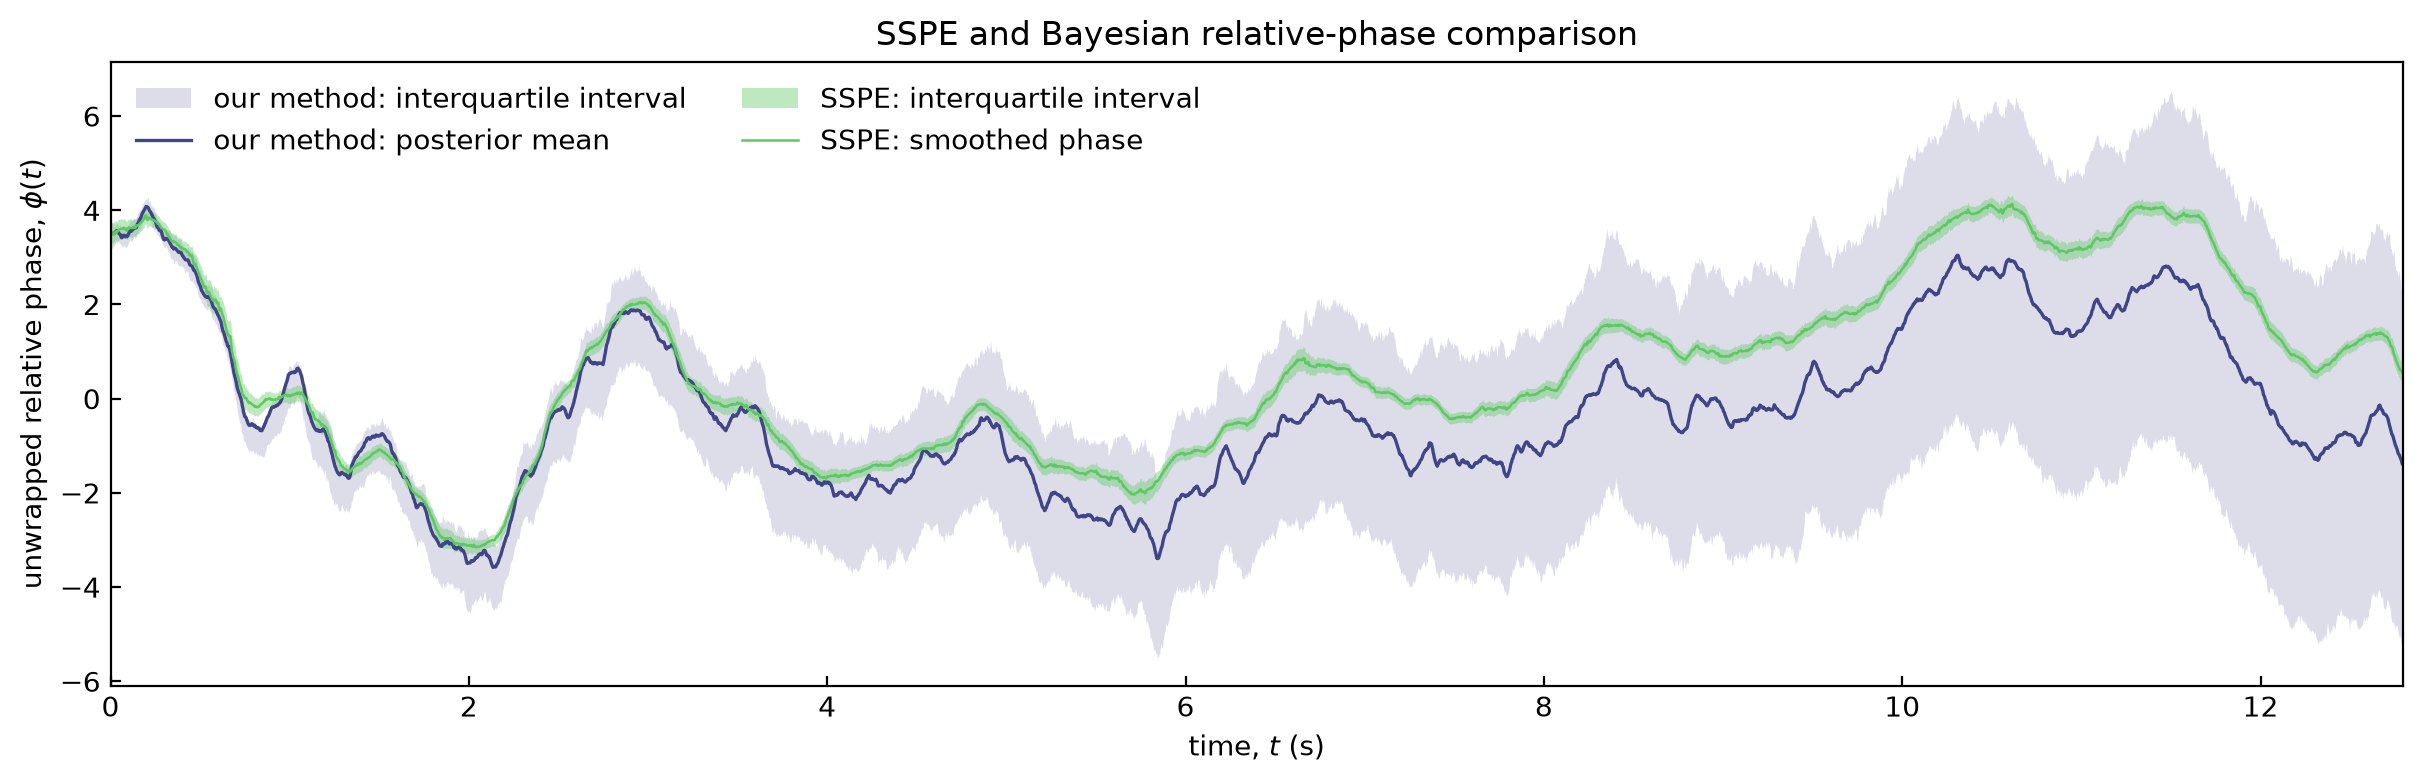

In [19]:
fig, ax = plt.subplots(figsize=(12, 3.8), constrained_layout=True)
ax.fill_between(
    time,
    inferred_phase_lo,
    inferred_phase_hi,
    color=cmap(0.2),
    alpha=0.18,
    lw=0,
    label='our method: interquartile interval',
)
ax.plot(
    time,
    inferred_phase_mean,
    color=cmap(0.2),
    lw=1.2,
    label='our method: posterior mean',
)
ax.fill_between(
    time,
    sspe_iqr_lo,
    sspe_iqr_hi,
    color=cmap(0.75),
    alpha=0.4,
    lw=0,
    label='SSPE: interquartile interval',
)
ax.plot(
    time,
    relative_phase_sspe,
    color=cmap(0.75),
    lw=0.9,
    label='SSPE: smoothed phase',
)
ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\phi(t)$',
    title='SSPE and Bayesian relative-phase comparison',
    xlim=(time[0], time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False, ncol=2)
plt.show()

#### Publication plot

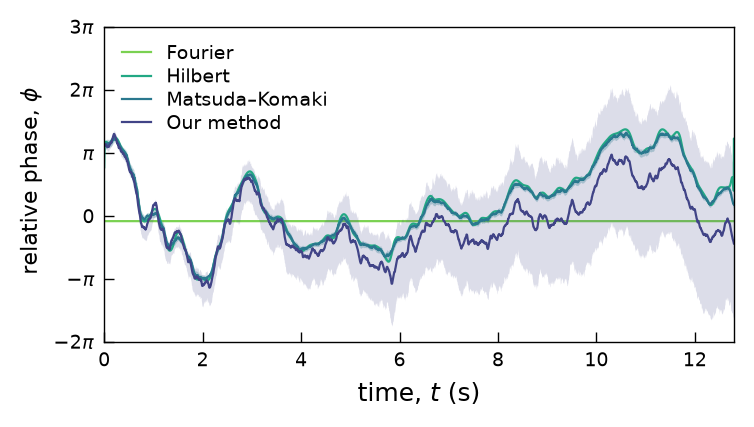

Hilbert branch shift: 0 × 2π
Fourier branch shift: 0 × 2π
Saved publication figure to plots/RelativePhaseComparison.pdf


In [20]:
hilbert_result_path = Path('data/hilbert_relative_phase_b1_zero.npz')
if not hilbert_result_path.exists():
    raise FileNotFoundError(
        f'{hilbert_result_path} does not exist. Run the Hilbert notebook '
        'through its B1=0 export cell first.'
    )

required_hilbert_keys = {
    'time',
    'relative_phase',
    'fourier_phase',
    'omega_map',
    'gauge_shift',
    'filter_order',
    'filter_band_hz',
}
with np.load(hilbert_result_path) as hilbert_result:
    missing_hilbert_keys = required_hilbert_keys.difference(hilbert_result.files)
    if missing_hilbert_keys:
        raise KeyError(
            f'{hilbert_result_path} is missing keys: '
            f'{sorted(missing_hilbert_keys)}'
        )
    hilbert_time = hilbert_result['time']
    hilbert_relative_phase = hilbert_result['relative_phase']
    fourier_phase = hilbert_result['fourier_phase'].item()
    hilbert_omega_map = hilbert_result['omega_map'].item()

if hilbert_time.ndim != 1 or hilbert_relative_phase.shape != hilbert_time.shape:
    raise ValueError('Hilbert time and relative-phase arrays must be matching 1D arrays.')
if not (np.all(np.isfinite(hilbert_time)) and np.all(np.isfinite(hilbert_relative_phase))):
    raise ValueError('Hilbert time and relative-phase arrays must contain only finite values.')
if not np.isfinite(fourier_phase):
    raise ValueError('Fourier phase must be finite.')
if not np.all(np.diff(hilbert_time) > 0):
    raise ValueError('Hilbert time values must be strictly increasing.')
if hilbert_time[0] > time[0] or hilbert_time[-1] < time[-1]:
    raise ValueError('Hilbert time grid does not cover the SSPE/Bayesian interval.')
if not np.isclose(hilbert_omega_map, omega_map, rtol=1e-12, atol=0):
    raise ValueError('Hilbert and Bayesian MAP frequencies do not match.')

hilbert_relative_phase_grid = np.interp(
    time, hilbert_time, hilbert_relative_phase
)
hilbert_branch_shift = 2 * np.pi * np.round(
    (inferred_phase_mean[0] - hilbert_relative_phase_grid[0]) / (2 * np.pi)
)
hilbert_relative_phase_grid += hilbert_branch_shift
fourier_branch_shift = 2 * np.pi * np.round(
    (inferred_phase_mean[0] - fourier_phase) / (2 * np.pi)
) - 2 * np.pi
fourier_relative_phase = np.full_like(
    time, fourier_phase + fourier_branch_shift
)

axes_width_cm, axes_height_cm = 8.0, 4.0
left_cm, right_cm, bottom_cm, top_cm = 1.7, 0.3, 1.2, 0.8
figure_width_cm = left_cm + axes_width_cm + right_cm
figure_height_cm = bottom_cm + axes_height_cm + top_cm
fig = plt.figure(figsize=(figure_width_cm * cm, figure_height_cm * cm))
ax = fig.add_axes([
    left_cm / figure_width_cm,
    bottom_cm / figure_height_cm,
    axes_width_cm / figure_width_cm,
    axes_height_cm / figure_height_cm,
])

ax.fill_between(
    time,
    inferred_phase_lo,
    inferred_phase_hi,
    color=cmap(0.2),
    alpha=0.18,
    lw=0,
)
ax.fill_between(
    time,
    sspe_iqr_lo,
    sspe_iqr_hi,
    color=cmap(0.4),
    alpha=0.3,
    lw=0,
)
ax.plot(
    time,
    fourier_relative_phase,
    color=cmap(0.8),
    lw=0.8,
    label='Fourier',
    zorder=-10,
)
ax.plot(
    time,
    hilbert_relative_phase_grid,
    color=cmap(0.6),
    lw=0.8,
    label='Hilbert',
)
ax.plot(
    time,
    relative_phase_sspe,
    color=cmap(0.4),
    lw=0.8,
    label='Matsuda–Komaki',
)
ax.plot(
    time,
    inferred_phase_mean,
    color=cmap(0.2),
    lw=0.8,
    label='Our method',
)
ax.set_xlabel('time, $t$ (s)', fontsize=9)
ax.set_ylabel(r' relative phase, $\phi$', fontsize=8)
ax.set_xlim(time[0], time[-1])
ax.set_ylim(-2*np.pi, 3*np.pi)
ax.set_yticks([-2*np.pi, -np.pi, 0, np.pi, 2*np.pi, 3*np.pi])
ax.set_yticklabels([r'$-2\pi$',r'$-\pi$', '0', r'$\pi$', r'$2\pi$', r'$3\pi$'])
ax.tick_params(
    axis='both', which='both', direction='in', width=0.5, labelsize=7
)
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
ax.legend(
    loc=2,
    frameon=False,
    fontsize=7,
    labelspacing=0.2,
    handlelength=1.5,
)

publication_path = Path('plots/RelativePhaseComparison.pdf')
fig.savefig(publication_path)
plt.show()
print(f'Hilbert branch shift: {hilbert_branch_shift / (2 * np.pi):.0f} × 2π')
print(f'Fourier branch shift: {fourier_branch_shift / (2 * np.pi):.0f} × 2π')
print(f'Saved publication figure to {publication_path}')

# Model Criticism

For a stable linear oscillator, $a<1$ controls the decay of state memory, while isotropic process noise continually re-excites both coordinates. At stationarity, each coordinate is Gaussian with variance $q/(1-a^2)$, so the amplitude is Rayleigh distributed rather than concentrated around a nonzero limit-cycle radius. Its coefficient of variation is therefore fixed at $\sqrt{(4-\pi)/\pi}\approx0.523$, independent of scale.

The simulations below ask whether the fitted model produces amplitude variability, low-amplitude episodes, or loss of coherence inconsistent with the hippocampal theta component. The constant-amplitude sinusoid is a qualitative limit-cycle reference only, not a fitted alternative model.

In [21]:
theta_damping = fit['damping'][theta_component]
theta_process_variance = fit['process_variances'][theta_component]
theta_decay_time = -(1 / sampling_frequency) / np.log(theta_damping)
theta_decay_cycles = theta_decay_time * theta_frequency_sspe
theta_stationary_variance = theta_process_variance / (1 - theta_damping**2)
theta_rayleigh_scale = np.sqrt(theta_stationary_variance)

print(f'Theta damping factor:       {theta_damping:.6f} per sample')
print(f'Correlation decay time:     {theta_decay_time:.3f} s')
print(f'Correlation decay in cycles: {theta_decay_cycles:.2f}')
print(f'Stationary amplitude CV:    {np.sqrt((4 - np.pi) / np.pi):.3f}')

Theta damping factor:       0.995454 per sample
Correlation decay time:     0.702 s
Correlation decay in cycles: 5.80
Stationary amplitude CV:    0.523


## Single Simulated Trajectory

In [22]:
simulation_rng = np.random.default_rng(20260730)
representative = SSPE.simulate_sspe(
    n_samples,
    sampling_frequency,
    fit['frequencies'],
    fit['damping'],
    fit['process_variances'],
    fit['observation_variance'],
    rng=simulation_rng,
)

observed_theta_state = (
    fit['smoother']['smoothed_mean'][:, 2 * theta_component]
    + 1j * fit['smoother']['smoothed_mean'][:, 2 * theta_component + 1]
)
observed_theta_amplitude = np.abs(observed_theta_state)
reference_amplitude = np.median(observed_theta_amplitude)
reference_phase = np.angle(observed_theta_state[0])
limit_cycle_reference = reference_amplitude * np.cos(
    omega_sspe * time + reference_phase
)

focus_window = time <= 2.0

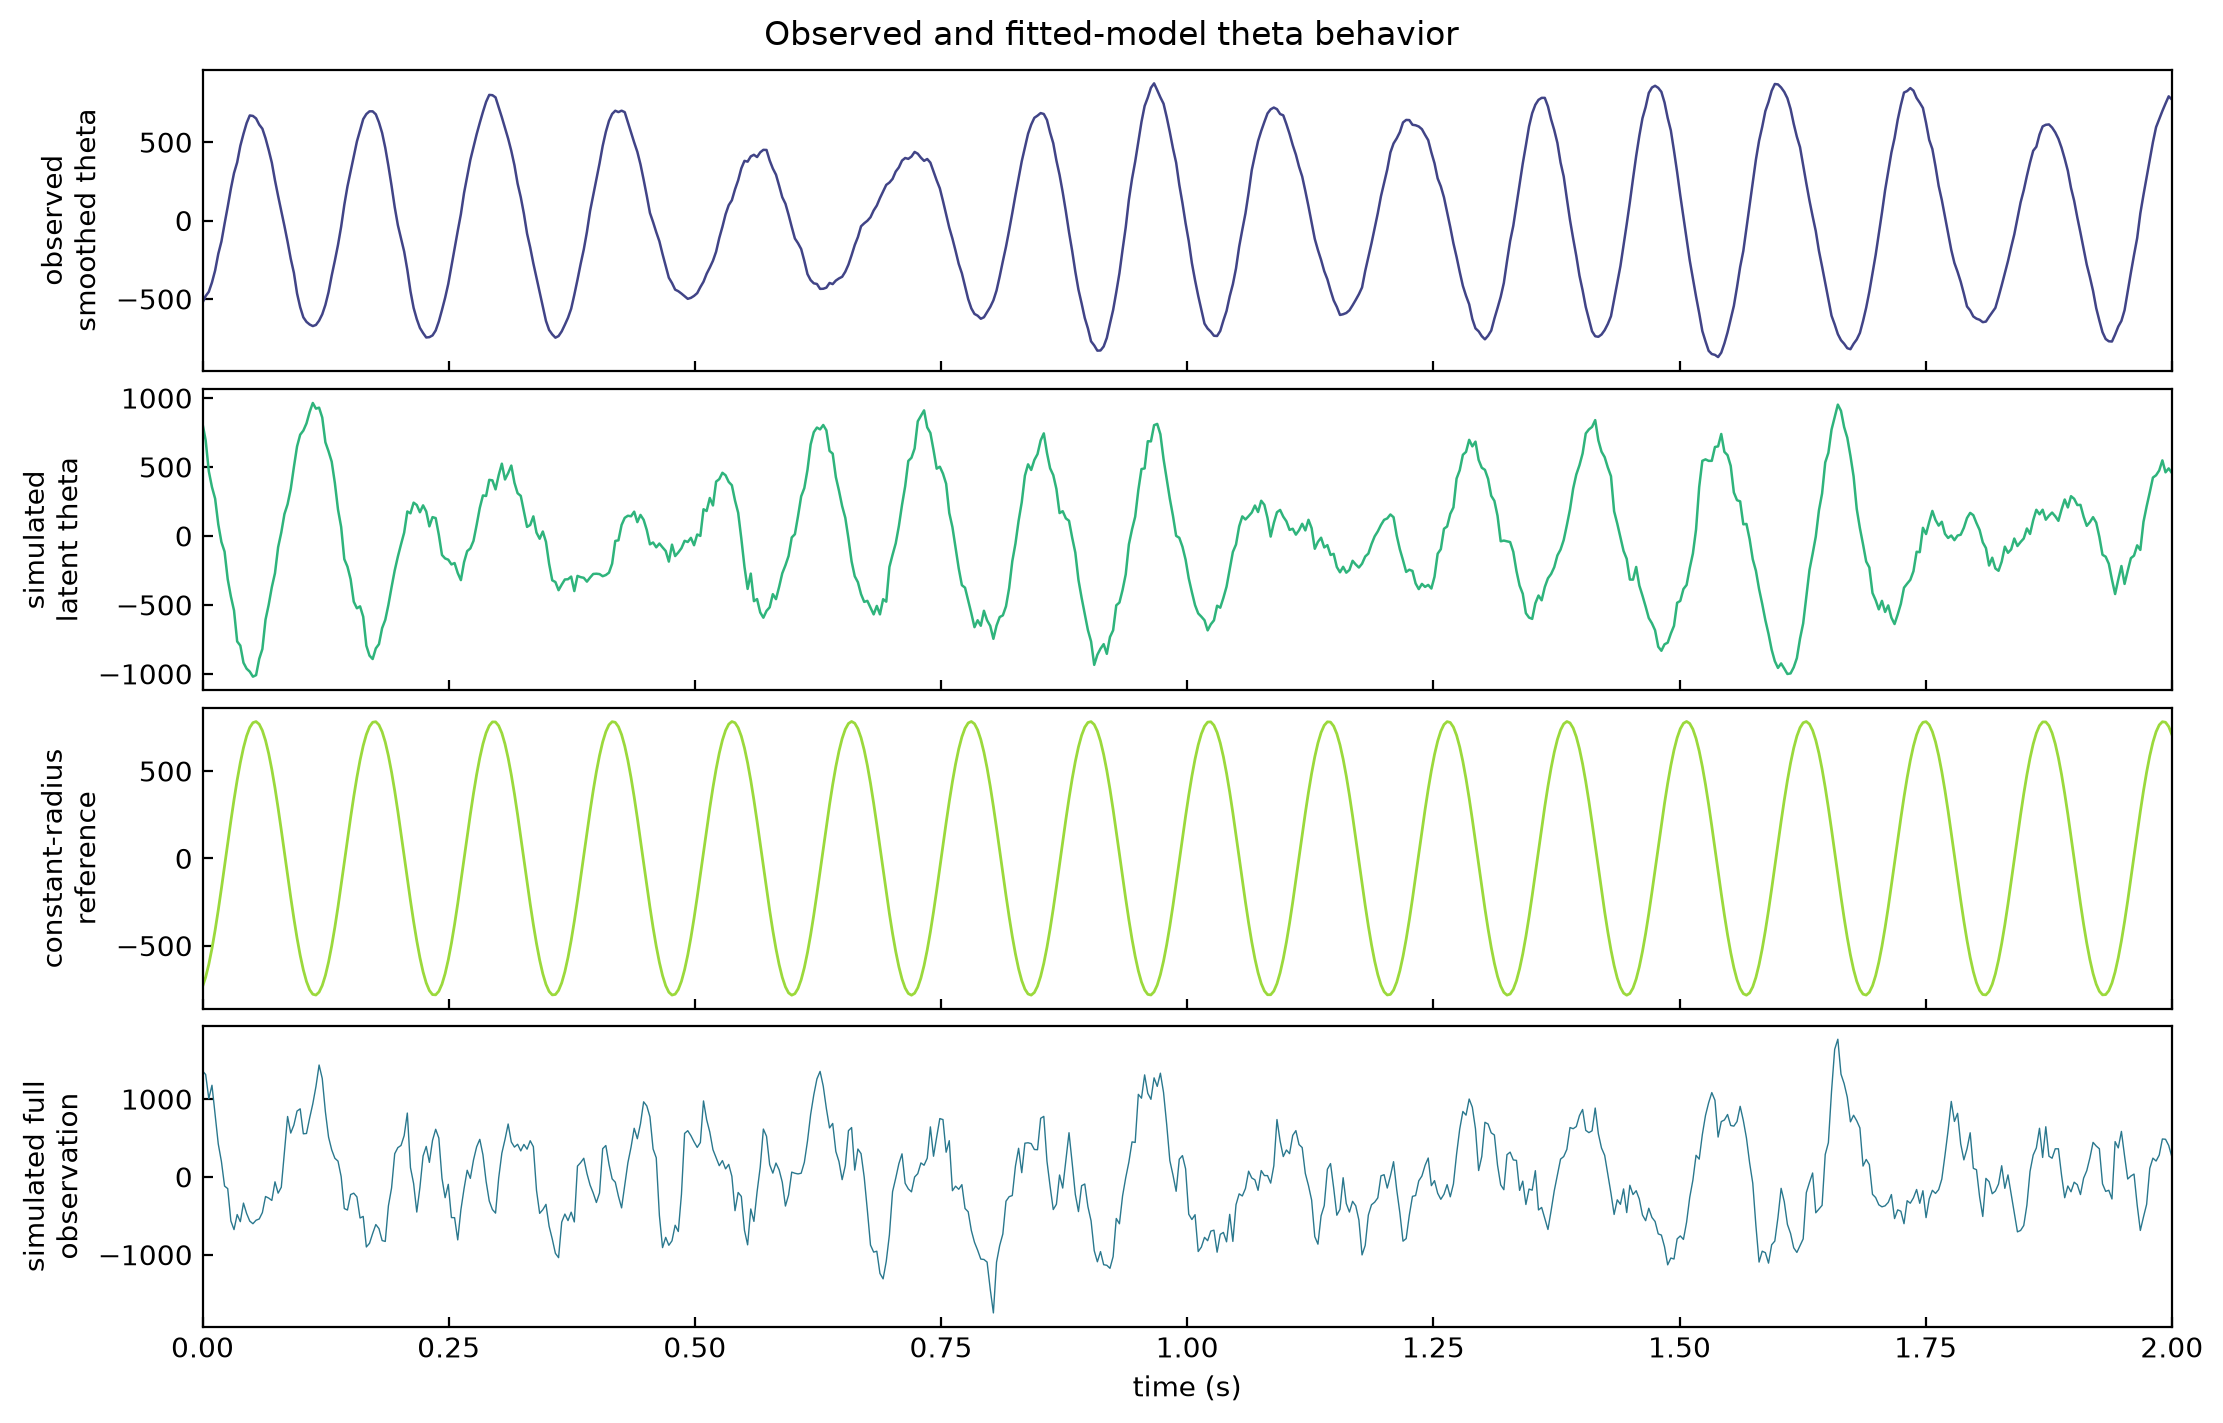

In [23]:
fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
axes[0].plot(
    time[focus_window],
    fit['smoothed_components'][focus_window, theta_component],
    color=cmap(0.2),
    lw=0.9,
)
axes[0].set_ylabel('observed\nsmoothed theta')

axes[1].plot(
    time[focus_window],
    representative['components'][focus_window, theta_component],
    color=cmap(0.65),
    lw=0.9,
)
axes[1].set_ylabel('simulated\nlatent theta')

axes[2].plot(
    time[focus_window],
    limit_cycle_reference[focus_window],
    color=cmap(0.85),
    lw=1,
)
axes[2].set_ylabel('constant-radius\nreference')

axes[3].plot(
    time[focus_window],
    representative['observation'][focus_window],
    color=cmap(0.4),
    lw=0.5,
)
axes[3].set(
    xlabel='time (s)',
    ylabel='simulated full\nobservation',
    xlim=(time[focus_window][0], time[focus_window][-1]),
)
for ax in axes:
    ax.tick_params(direction='in')
fig.suptitle('Observed and fitted-model theta behavior')
plt.show()

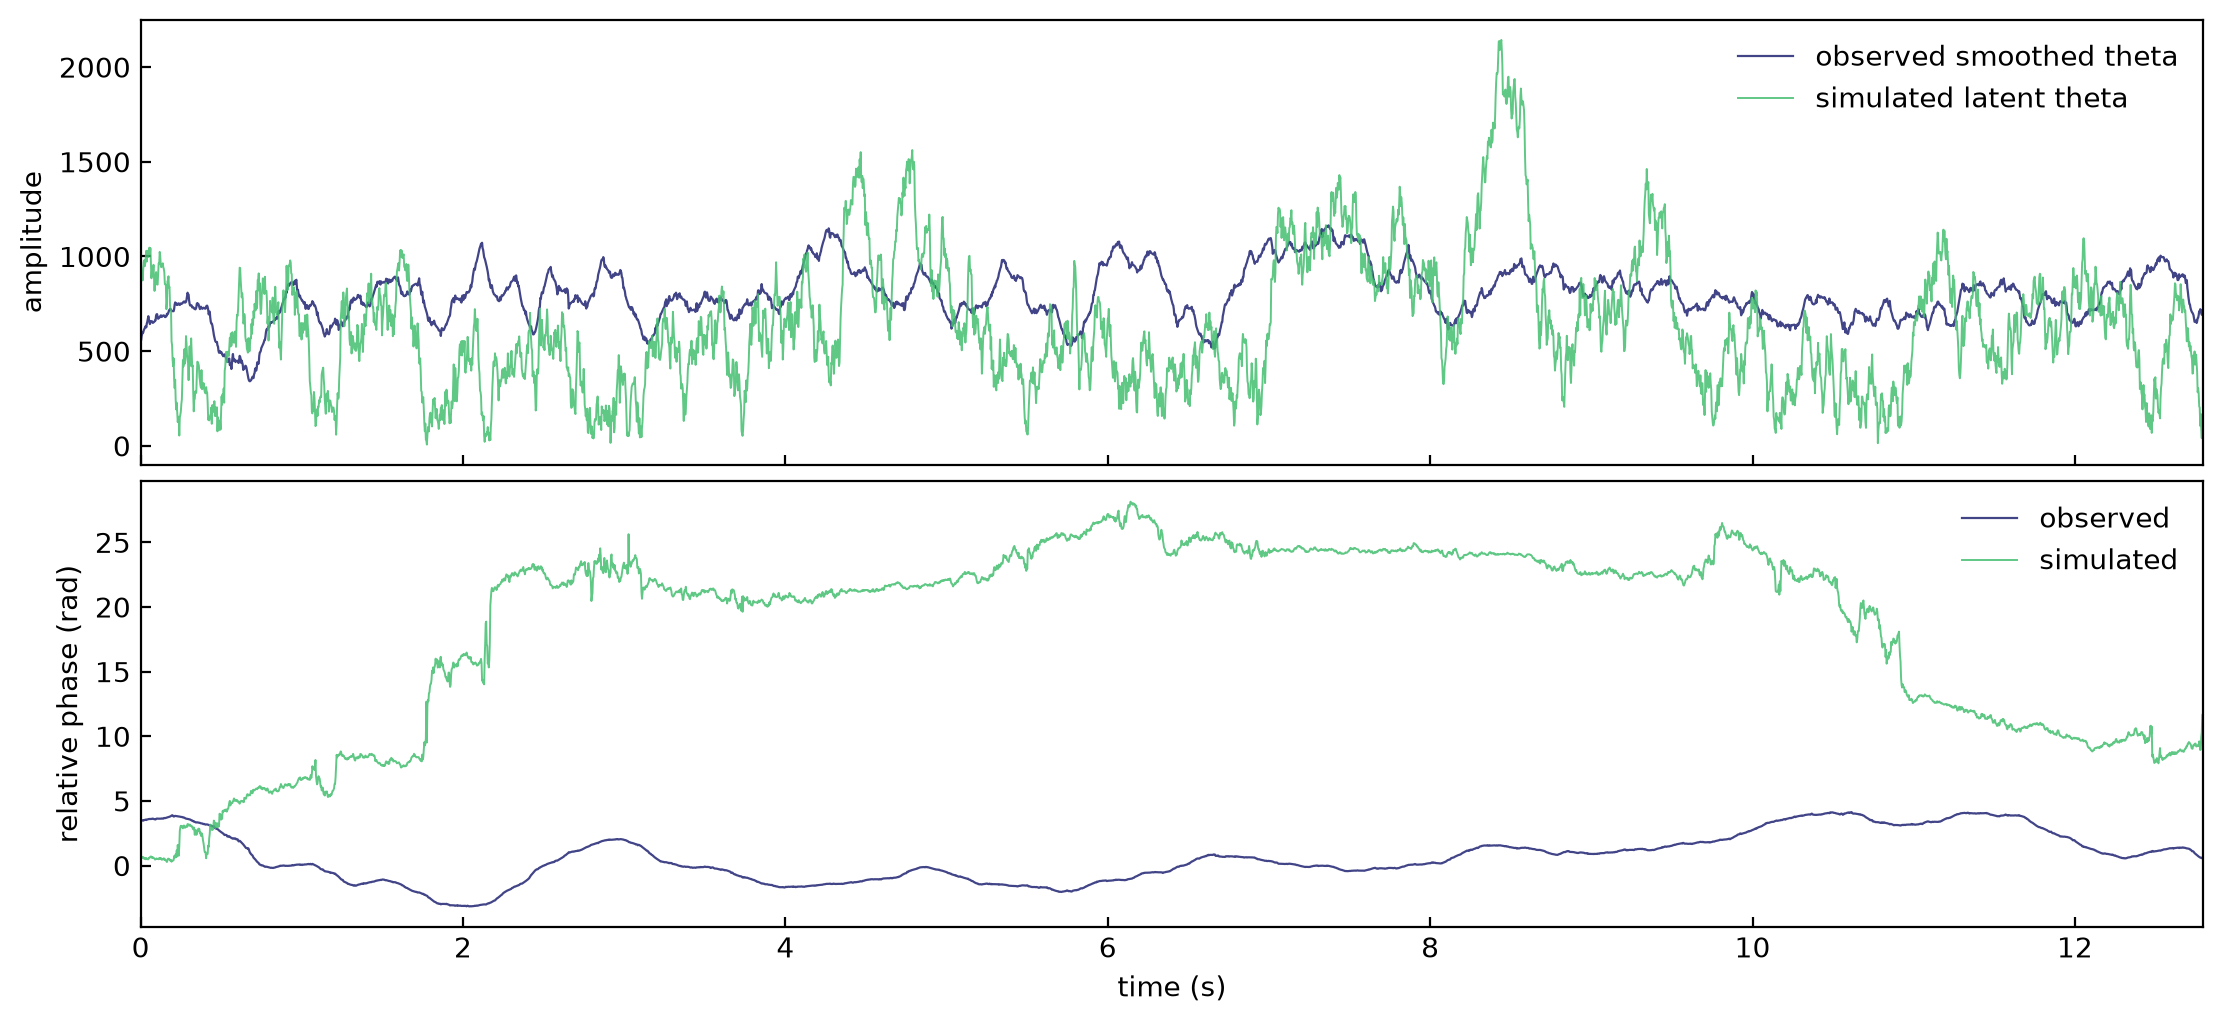

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
axes[0].plot(
    time,
    observed_theta_amplitude,
    color=cmap(0.2),
    lw=0.8,
    label='observed smoothed theta',
)
axes[0].plot(
    time,
    representative['amplitudes'][:, theta_component],
    color=cmap(0.7),
    lw=0.7,
    alpha=0.85,
    label='simulated latent theta',
)
axes[0].set_ylabel('amplitude')
axes[0].legend(frameon=False)

simulated_relative_phase = (
    representative['phases_unwrapped'][:, theta_component] - omega_sspe * time
)
axes[1].plot(time, relative_phase_sspe, color=cmap(0.2), lw=0.8, label='observed')
axes[1].plot(
    time,
    simulated_relative_phase,
    color=cmap(0.7),
    lw=0.7,
    alpha=0.85,
    label='simulated',
)
axes[1].set(
    xlabel='time (s)',
    ylabel='relative phase (rad)',
    xlim=(time[0], time[-1]),
)
axes[1].legend(frameon=False)
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

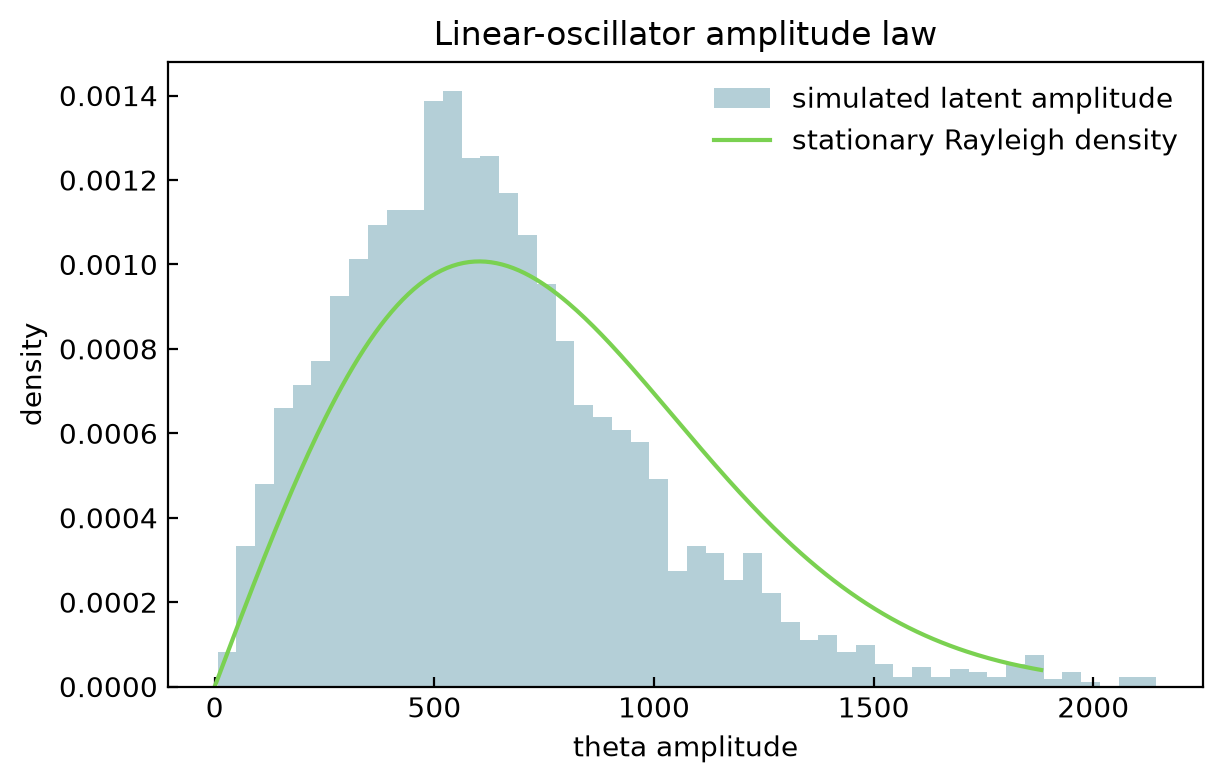

In [25]:
fig, ax = plt.subplots(figsize=(6, 3.8), constrained_layout=True)
simulated_theta_amplitude = representative['amplitudes'][:, theta_component]
amplitude_grid = np.linspace(0, np.percentile(simulated_theta_amplitude, 99.5), 300)
rayleigh_density = (
    amplitude_grid / theta_rayleigh_scale**2
    * np.exp(-amplitude_grid**2 / (2 * theta_rayleigh_scale**2))
)
ax.hist(
    simulated_theta_amplitude,
    bins=50,
    density=True,
    color=cmap(0.4),
    alpha=0.35,
    label='simulated latent amplitude',
)
ax.plot(
    amplitude_grid,
    rayleigh_density,
    color=cmap(0.8),
    lw=1.5,
    label='stationary Rayleigh density',
)
ax.set(xlabel='theta amplitude', ylabel='density', title='Linear-oscillator amplitude law')
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

## Many Simulated Trajectories

The next checks use 100 stationary simulations from the fitted full model with parameters held fixed. The known latent states test the generative model directly against its Rayleigh amplitude law and $a^\ell$ coherence. Each noisy simulated observation is also centered and passed through the same fixed-parameter Kalman filter and RTS smoother used for the observed signal. Those smoothed simulations provide the apples-to-apples comparison with the smoothed state inferred from the EEG.

In [26]:
final_stationary_variances = fit['process_variances'] / (1 - fit['damping']**2)
final_initial_covariance = np.diag(np.repeat(final_stationary_variances, 2))

def smooth_with_fitted_parameters(observation_values):
    filter_result = SSPE.kalman_filter(
        observation_values,
        fit['transition'],
        fit['process_covariance'],
        fit['observation'],
        fit['observation_variance'],
        initial_mean=np.zeros(fit['transition'].shape[0]),
        initial_covariance=final_initial_covariance,
    )
    return SSPE.rts_smoother(filter_result, fit['transition'])

def normalized_complex_coherence(complex_state, max_lag):
    denominator = np.mean(np.abs(complex_state) ** 2)
    coherence = np.empty(max_lag + 1)
    coherence[0] = 1.0
    for lag in range(1, max_lag + 1):
        coherence[lag] = np.abs(
            np.mean(complex_state[lag:] * np.conj(complex_state[:-lag]))
        ) / denominator
    return coherence

def pooled_complex_coherence(complex_states, max_lag):
    denominator = np.mean(np.abs(complex_states) ** 2)
    coherence = np.empty(max_lag + 1)
    coherence[0] = 1.0
    for lag in range(1, max_lag + 1):
        coherence[lag] = np.abs(
            np.mean(complex_states[:, lag:] * np.conj(complex_states[:, :-lag]))
        ) / denominator
    return coherence

def amplitude_statistics(amplitude):
    return (
        np.std(amplitude) / np.mean(amplitude),
        np.mean(amplitude < 0.5 * np.median(amplitude)),
    )

In [27]:
observed_fixed_smoother = smooth_with_fitted_parameters(signal_centered)
observed_fixed_state = (
    observed_fixed_smoother['smoothed_mean'][:, 2 * theta_component]
    + 1j * observed_fixed_smoother['smoothed_mean'][:, 2 * theta_component + 1]
)
observed_fixed_amplitude = np.abs(observed_fixed_state)

n_replicates = 100
max_coherence_lag = int(2 * sampling_frequency)
coherence_lags = np.arange(max_coherence_lag + 1)
coherence_times = coherence_lags / sampling_frequency
spectrum_frequencies = np.fft.rfftfreq(n_samples, d=1 / sampling_frequency)

simulated_spectra = np.empty((n_replicates, spectrum_frequencies.size))
simulated_latent_states = np.empty((n_replicates, n_samples), dtype=complex)
simulated_latent_amplitudes = np.empty((n_replicates, n_samples))
simulated_smoothed_states = np.empty((n_replicates, n_samples), dtype=complex)
simulated_smoothed_amplitudes = np.empty((n_replicates, n_samples))
simulated_latent_coherences = np.empty(
    (n_replicates, max_coherence_lag + 1)
)
simulated_coherences = np.empty((n_replicates, max_coherence_lag + 1))
simulated_amplitude_cv = np.empty(n_replicates)
simulated_low_amplitude_occupancy = np.empty(n_replicates)

ensemble_rng = np.random.default_rng(20260731)
for replicate in range(n_replicates):
    simulation = SSPE.simulate_sspe(
        n_samples,
        sampling_frequency,
        fit['frequencies'],
        fit['damping'],
        fit['process_variances'],
        fit['observation_variance'],
        rng=ensemble_rng,
    )
    simulated_signal = simulation['observation'] - simulation['observation'].mean()
    simulated_fft = np.fft.rfft(simulated_signal)
    simulated_spectra[replicate] = np.abs(simulated_fft) ** 2 / (
        sampling_frequency * n_samples
    )
    simulated_spectra[replicate, 1:-1] *= 2

    latent_state = (
        simulation['states'][:, 2 * theta_component]
        + 1j * simulation['states'][:, 2 * theta_component + 1]
    )
    simulated_latent_states[replicate] = latent_state
    simulated_latent_amplitudes[replicate] = np.abs(latent_state)
    simulated_latent_coherences[replicate] = normalized_complex_coherence(
        latent_state, max_coherence_lag
    )

    simulated_smoother = smooth_with_fitted_parameters(simulated_signal)
    simulated_state = (
        simulated_smoother['smoothed_mean'][:, 2 * theta_component]
        + 1j * simulated_smoother['smoothed_mean'][:, 2 * theta_component + 1]
    )
    simulated_amplitude = np.abs(simulated_state)
    simulated_smoothed_states[replicate] = simulated_state
    simulated_smoothed_amplitudes[replicate] = simulated_amplitude
    simulated_coherences[replicate] = normalized_complex_coherence(
        simulated_state, max_coherence_lag
    )
    (
        simulated_amplitude_cv[replicate],
        simulated_low_amplitude_occupancy[replicate],
    ) = amplitude_statistics(simulated_amplitude)

observed_fft = np.fft.rfft(signal_centered)
observed_spectrum = np.abs(observed_fft) ** 2 / (sampling_frequency * n_samples)
observed_spectrum[1:-1] *= 2
observed_coherence = normalized_complex_coherence(
    observed_fixed_state, max_coherence_lag
)
observed_amplitude_cv, observed_low_amplitude_occupancy = amplitude_statistics(
    observed_fixed_amplitude
)
pooled_latent_coherence = pooled_complex_coherence(
    simulated_latent_states, max_coherence_lag
)

### Visualization of Simulated Trajectories

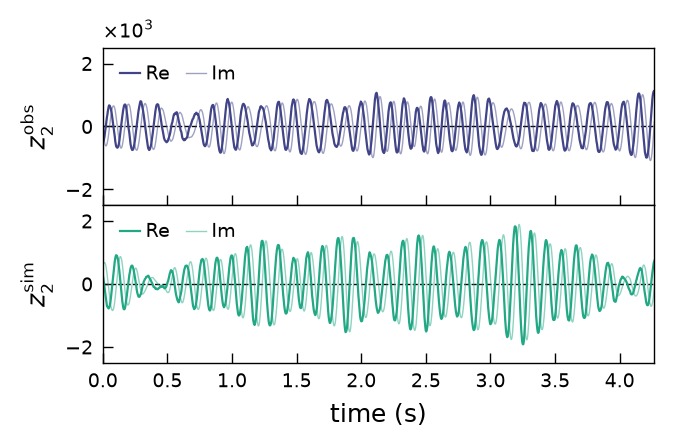

Saved observed/simulated z2 figure to plots/SSPE_z2_trajectories.pdf


In [28]:
# Exact combined axis dimensions
ax_w = 7.0 * cm
total_ax_h = 2 * 2.0 * cm

# Figure margins
left = 1.5 * cm
right = 0.3 * cm
bottom = 1.2 * cm
top = 0.4 * cm

fig_w = left + ax_w + right
fig_h = bottom + total_ax_h + top

fig, axes = plt.subplots(
    2,
    1,
    figsize=(fig_w, fig_h),
    sharex=True,
    sharey=True,
    gridspec_kw={"hspace": 0},
)
fig.subplots_adjust(
    left=left / fig_w,
    right=1 - right / fig_w,
    bottom=bottom / fig_h,
    top=1 - top / fig_h,
    hspace=0,
)

axes[0].plot(
    time,
    observed_theta_state.real,
    color=cmap(0.2),
    lw=0.8,
    alpha=1,
    label=r'$\mathrm{Re}$',
)
axes[0].plot(
    time,
    observed_theta_state.imag,
    color=cmap(0.2),
    lw=0.5,
    ls='-',
    alpha=0.5,
    label=r'$\mathrm{Im}$',
)
axes[1].plot(
    time,
    simulated_smoothed_states[0].real,
    color=cmap(0.6),
    lw=0.8,
    alpha=1,
    label=r'$\mathrm{Re}$',
)
axes[1].plot(
    time,
    simulated_smoothed_states[0].imag,
    color=cmap(0.6),
    lw=0.5,
    ls='-',
    alpha=0.5,
    label=r'$\mathrm{Im}$',
)

# thousands_formatter = FuncFormatter(lambda value, position: f'{value / 1000:g}')
for ax in axes:
    ax.set_ylim(-2500, 2500)
    ax.set_yticks([-2000,  0, 2000])
    ax.yaxis.set_major_formatter(thousands_formatter)
    ax.tick_params(
        axis='both', which='both', direction='in', width=0.5, labelsize=7
    )
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)

axes[0].axhline(0, color='black', linestyle='--', linewidth=0.5, zorder=-10)
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.5, zorder=-10)

axes[0].set_ylabel(r'$z_2^{\mathrm{obs}}$', fontsize=9)
axes[1].set_ylabel(r'$z_2^{\mathrm{sim}}$', fontsize=9)
axes[1].set_xlim(time[0], time[-1] / 3)
axes[1].set_xlabel('time (s)', fontsize=9)
axes[0].legend(
    loc='upper left',
    ncol=2,
    fontsize=7,
    frameon=False,
    handlelength=1.0,
    handletextpad=0.3,
    columnspacing=0.8,
)
axes[1].legend(
    loc='upper left',
    ncol=2,
    fontsize=7,
    handletextpad=0.3,
    handlelength=1.0,
    columnspacing=0.8,
    frameon=False,
)
axes[0].text(
    0.0,
    1.03,
    r'$\times 10^{3}$',
    transform=axes[0].transAxes,
    ha='left',
    va='bottom',
    fontsize=7,
)

z2_trajectory_path = Path('plots/SSPE_z2_trajectories.pdf')
fig.savefig(z2_trajectory_path)
plt.show()
print(f'Saved observed/simulated z2 figure to {z2_trajectory_path}')

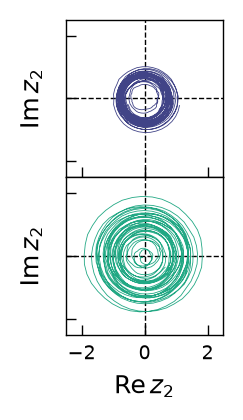

Saved observed/simulated z2 complex-plane figure to plots/SSPE_z2_complex_plane.pdf


In [29]:
imax = simulated_smoothed_states[0].shape[0] // 3

# Exact axis dimensions
ax_w = 2.0 * cm
total_ax_h = 2 * 2.0 * cm

# Figure margins
left = 1.5 * cm
right = 0.3 * cm
bottom = 1.2 * cm
top = 0.4 * cm

fig_w = left + ax_w + right
fig_h = bottom + total_ax_h + top
fig, axes = plt.subplots(
    2,
    1,
    figsize=(fig_w, fig_h),
    sharex=True,
    sharey=True,
    gridspec_kw={'hspace': 0},
)
fig.subplots_adjust(
    left=left / fig_w,
    right=1 - right / fig_w,
    bottom=bottom / fig_h,
    top=1 - top / fig_h,
    hspace=0,
)

axes[0].plot(
    observed_theta_state.real[:imax],
    observed_theta_state.imag[:imax],
    color=cmap(0.2),
    lw=0.3,
    alpha=1,
)
axes[1].plot(
    simulated_smoothed_states[0].real[:imax],
    simulated_smoothed_states[0].imag[:imax],
    color=cmap(0.6),
    lw=0.3,
    alpha=1,
)

# thousands_formatter = FuncFormatter(lambda value, position: f'{value / 1000:g}')
for ax in axes:
    ax.set_xlim(-2500, 2500)
    ax.set_ylim(-2500, 2500)
    ax.set_xticks([-2000, 0, 2000])
    ax.set_yticks([-2000, 0, 2000])
    ax.xaxis.set_major_formatter(thousands_formatter)
    ax.yaxis.set_major_formatter(thousands_formatter)
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(
        axis='both', which='both', direction='in', width=0.5, labelsize=7
    )
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)

axes[0].axvline(0, color='black', linestyle='--', linewidth=0.5, zorder=-10)
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.5, zorder=-10)
axes[1].axvline(0, color='black', linestyle='--', linewidth=0.5, zorder=-10)
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.5, zorder=-10)

axes[0].set_ylabel(r'$\mathrm{Im}\,z_2$', fontsize=9)
axes[1].set_ylabel(r'$\mathrm{Im}\,z_2$', fontsize=9)
axes[1].set_xlabel(r'$\mathrm{Re}\,z_2$', fontsize=9)
ax.set_yticklabels([])
axes[0].text(
    0.0,
    1.03,
    '', #r'$\times 10^{3}$',
    transform=axes[0].transAxes,
    ha='left',
    va='bottom',
    fontsize=7,
)

z2_complex_plane_path = Path('plots/SSPE_z2_complex_plane.pdf')
fig.savefig(z2_complex_plane_path)
plt.show()
print(f'Saved observed/simulated z2 complex-plane figure to {z2_complex_plane_path}')


### Power Spectral Density

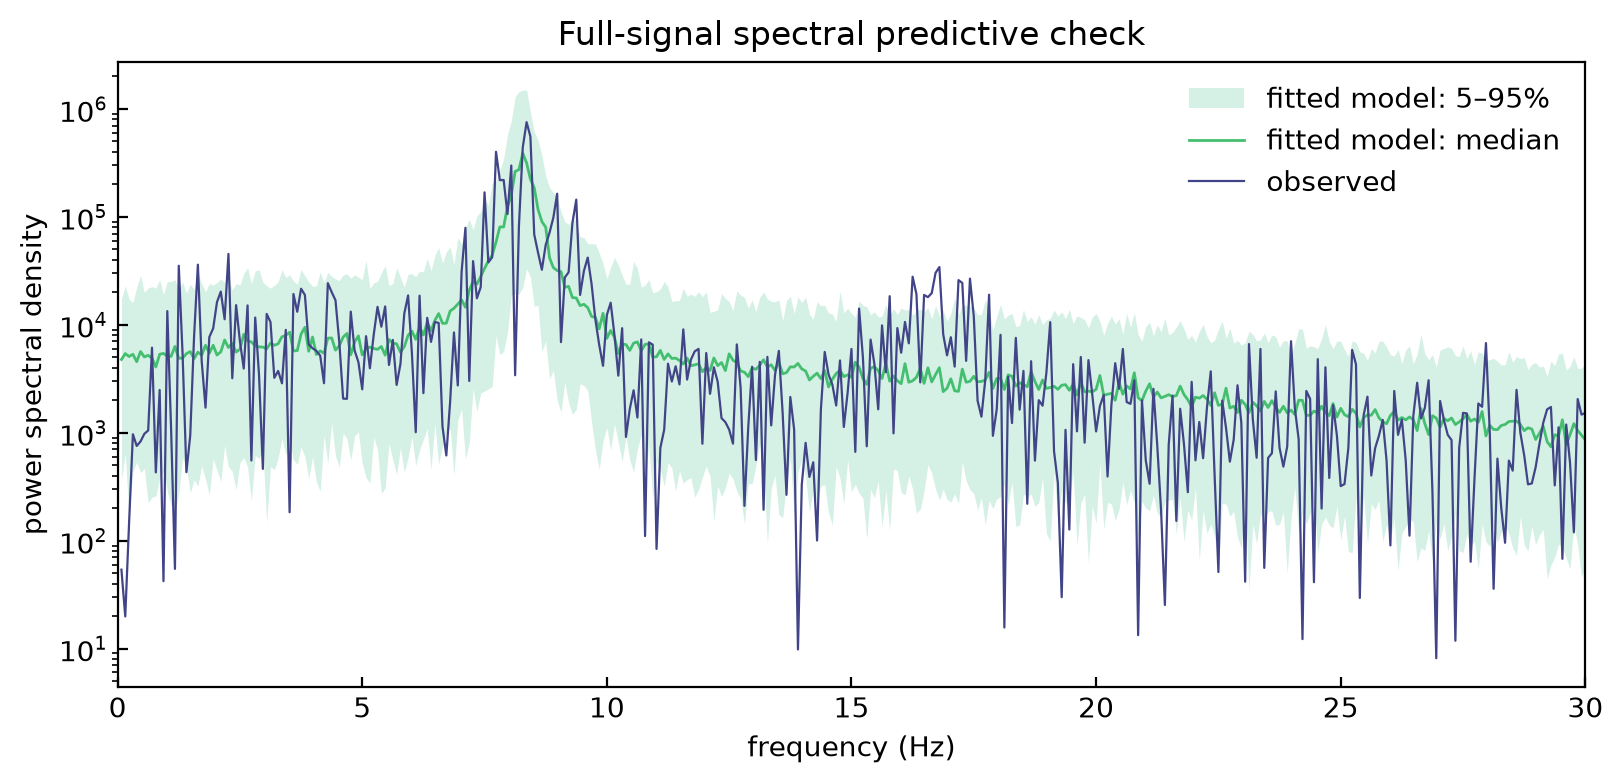

In [30]:
spectrum_lo, spectrum_median, spectrum_hi = np.percentile(
    simulated_spectra, [5, 50, 95], axis=0
)
spectrum_window = (spectrum_frequencies > 0) & (spectrum_frequencies <= 30)

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.fill_between(
    spectrum_frequencies[spectrum_window],
    spectrum_lo[spectrum_window],
    spectrum_hi[spectrum_window],
    color=cmap(0.65),
    alpha=0.2,
    lw=0,
    label='fitted model: 5–95%',
)
ax.semilogy(
    spectrum_frequencies[spectrum_window],
    spectrum_median[spectrum_window],
    color=cmap(0.7),
    lw=1,
    label='fitted model: median',
)
ax.semilogy(
    spectrum_frequencies[spectrum_window],
    observed_spectrum[spectrum_window],
    color=cmap(0.2),
    lw=0.8,
    label='observed',
)
ax.set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title='Full-signal spectral predictive check',
    xlim=(0, 30),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

### Amplitude Distribution

#### Initial plot

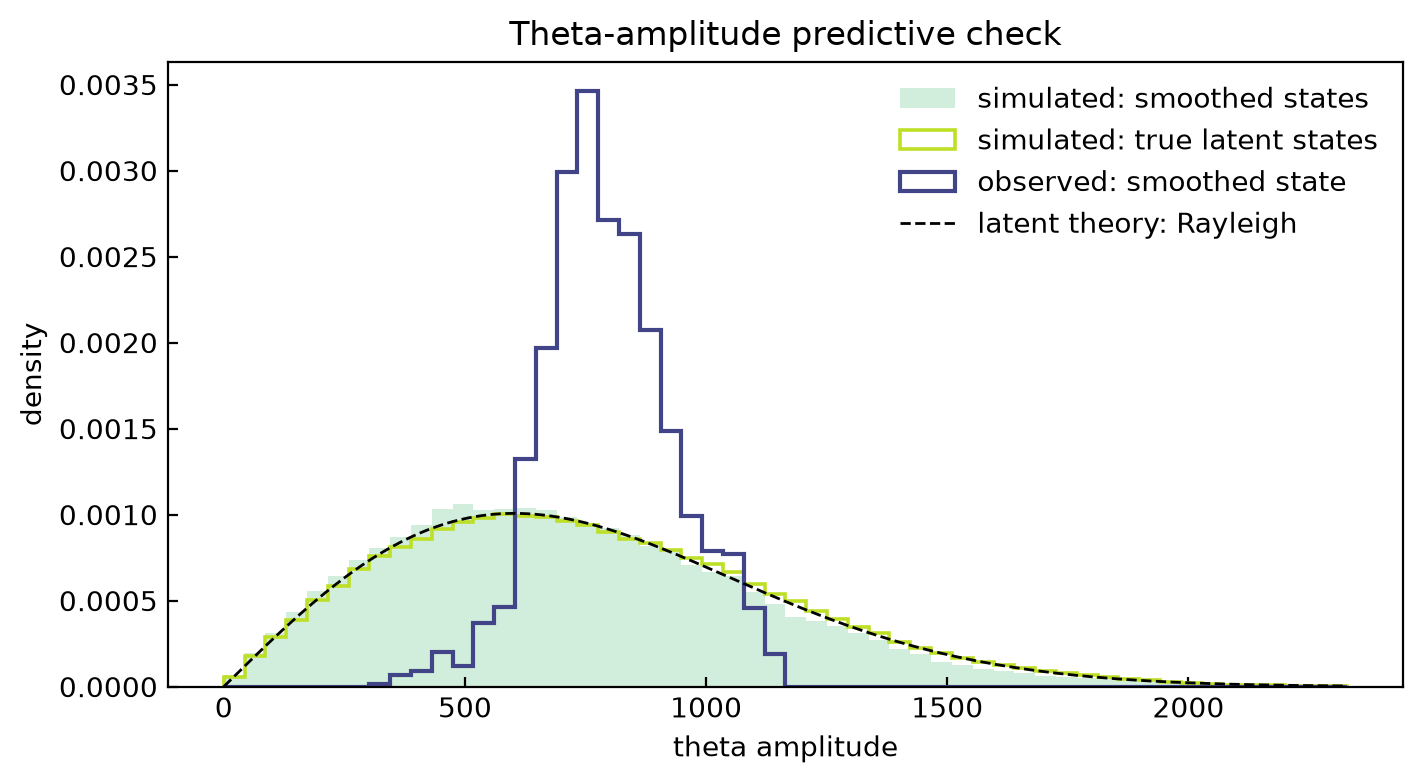

In [31]:
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
amplitude_upper = 1.2*max(
    np.percentile(observed_fixed_amplitude, 99.5),
    np.percentile(simulated_latent_amplitudes, 99.5),
    np.percentile(simulated_smoothed_amplitudes, 99.5),
)
amplitude_bins = np.linspace(0, amplitude_upper, 55)
amplitude_grid = np.linspace(0, amplitude_upper, 500)
stationary_rayleigh_density = (
    amplitude_grid / theta_rayleigh_scale**2
    * np.exp(-amplitude_grid**2 / (2 * theta_rayleigh_scale**2))
)
ax.hist(
    simulated_smoothed_amplitudes.ravel(),
    bins=amplitude_bins,
    density=True,
    color=cmap(0.7),
    alpha=0.25,
    label='simulated: smoothed states',
)
ax.hist(
    simulated_latent_amplitudes.ravel(),
    bins=amplitude_bins,
    density=True,
    histtype='step',
    color=cmap(0.9),
    lw=1.3,
    label='simulated: true latent states',
)
ax.hist(
    observed_fixed_amplitude,
    bins=amplitude_bins,
    density=True,
    histtype='step',
    color=cmap(0.2),
    lw=1.5,
    label='observed: smoothed state',
)
ax.plot(
    amplitude_grid,
    stationary_rayleigh_density,
    'k--',
    lw=1,
    label='latent theory: Rayleigh',
)
ax.set(
    xlabel='theta amplitude',
    ylabel='density',
    title='Theta-amplitude predictive check',
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

#### Publication plot

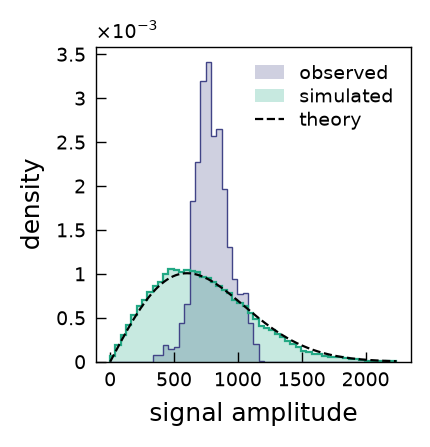

Saved publication figure to plots/ThetaAmplitudePredictiveCheck.pdf


In [36]:
amplitude_upper = 1.2*max(
    np.percentile(observed_fixed_amplitude, 99.5),
    np.percentile(simulated_smoothed_amplitudes, 99.5),
)
amplitude_bins = np.linspace(0, amplitude_upper, 55)
amplitude_grid = np.linspace(0, amplitude_upper, 500)
stationary_rayleigh_density = (
    amplitude_grid / theta_rayleigh_scale**2
    * np.exp(-amplitude_grid**2 / (2 * theta_rayleigh_scale**2))
)

axes_width_cm, axes_height_cm = 4.0, 4.0
left_cm, right_cm, bottom_cm, top_cm = 1.5, 0.3, 1.2, 0.4
figure_width_cm = left_cm + axes_width_cm + right_cm
figure_height_cm = bottom_cm + axes_height_cm + top_cm
fig = plt.figure(figsize=(figure_width_cm * cm, figure_height_cm * cm))
ax = fig.add_axes([
    left_cm / figure_width_cm,
    bottom_cm / figure_height_cm,
    axes_width_cm / figure_width_cm,
    axes_height_cm / figure_height_cm,
])

# Display -1000, 0, 1000 as -1, 0, 1
thousands_formatter = FuncFormatter(lambda value, position: f"{value * 1000:g}")

ax.hist(
    observed_fixed_amplitude,
    bins=amplitude_bins,
    density=True,
    color=cmap(0.2),
    alpha=0.25,
    label='observed',
)
ax.hist(
    simulated_smoothed_amplitudes.ravel(),
    bins=amplitude_bins,
    density=True,
    color=cmap(0.6),
    alpha=0.25,
    label='simulated',
)
ax.hist(
    observed_fixed_amplitude,
    bins=amplitude_bins,
    density=True,
    histtype='step',
    color=cmap(0.2),
    lw=0.5,
)
ax.hist(
    simulated_smoothed_amplitudes.ravel(),
    bins=amplitude_bins,
    density=True,
    histtype='step',
    color=cmap(0.6),
    lw=0.8,
)
ax.plot(
    amplitude_grid,
    stationary_rayleigh_density,
    'k--',
    lw=0.8,
    label='theory',
)
ax.set_xlabel('signal amplitude', fontsize=9)
ax.set_ylabel('density', fontsize=9)
ax.tick_params(
    axis='both', which='both', direction='in', width=0.5, labelsize=7
)
ax.yaxis.set_major_formatter(thousands_formatter)
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
ax.legend(
    loc=1,
    ncol=1,
    frameon=False,
    fontsize=7,
    labelspacing=0.2,
    handlelength=1.5,
)

# Show the common scale factor above the top panel only
ax.text(
    0.0,
    1.01,
    r"$\times 10^{-3}$",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=7,
)

amplitude_publication_path = Path(
    'plots/ThetaAmplitudePredictiveCheck.pdf'
)
fig.savefig(amplitude_publication_path)
plt.show()
print(f'Saved publication figure to {amplitude_publication_path}')

In [38]:
observed_fixed_amplitude.std()/observed_fixed_amplitude.mean()

np.float64(0.17238740406602354)

#### Posterior Predictive Check

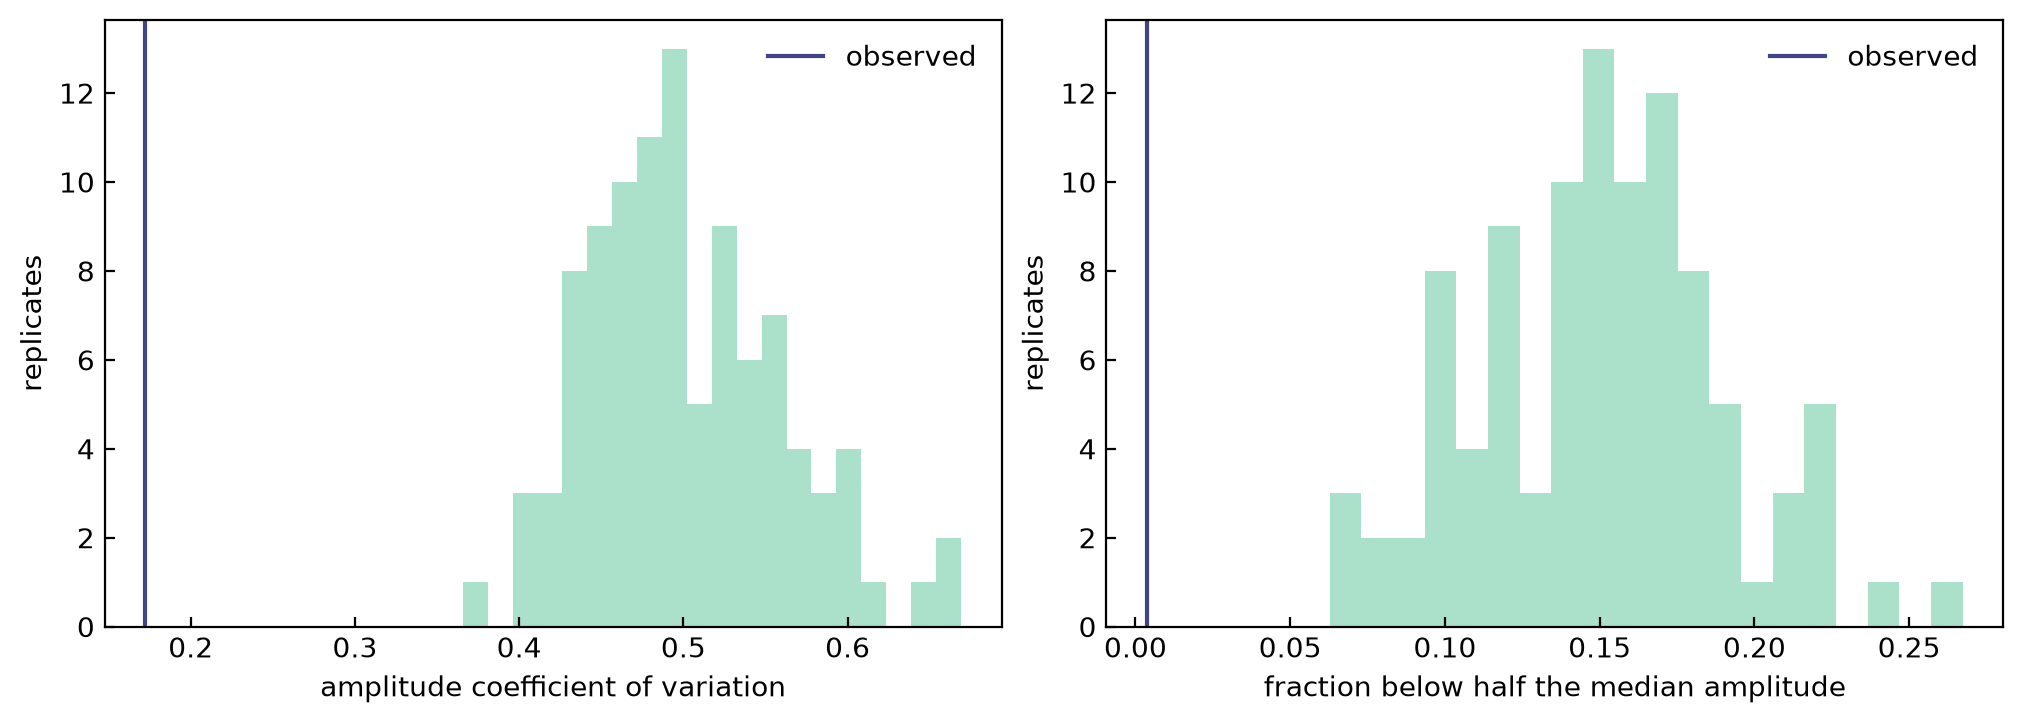

Observed amplitude CV: 0.172
Model percentile:      0.0%
Observed low-amplitude occupancy: 0.004
Model percentile:                 0.0%


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].hist(simulated_amplitude_cv, bins=20, color=cmap(0.65), alpha=0.4)
axes[0].axvline(observed_amplitude_cv, color=cmap(0.2), lw=1.5, label='observed')
axes[0].set(xlabel='amplitude coefficient of variation', ylabel='replicates')
axes[0].legend(frameon=False)

axes[1].hist(
    simulated_low_amplitude_occupancy,
    bins=20,
    color=cmap(0.65),
    alpha=0.4,
)
axes[1].axvline(
    observed_low_amplitude_occupancy,
    color=cmap(0.2),
    lw=1.5,
    label='observed',
)
axes[1].set(
    xlabel='fraction below half the median amplitude',
    ylabel='replicates',
)
axes[1].legend(frameon=False)
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

print(f'Observed amplitude CV: {observed_amplitude_cv:.3f}')
print(f'Model percentile:      {100 * np.mean(simulated_amplitude_cv <= observed_amplitude_cv):.1f}%')
print(f'Observed low-amplitude occupancy: {observed_low_amplitude_occupancy:.3f}')
print(
    'Model percentile:                 '
    f'{100 * np.mean(simulated_low_amplitude_occupancy <= observed_low_amplitude_occupancy):.1f}%'
)

### Temporal Correlations

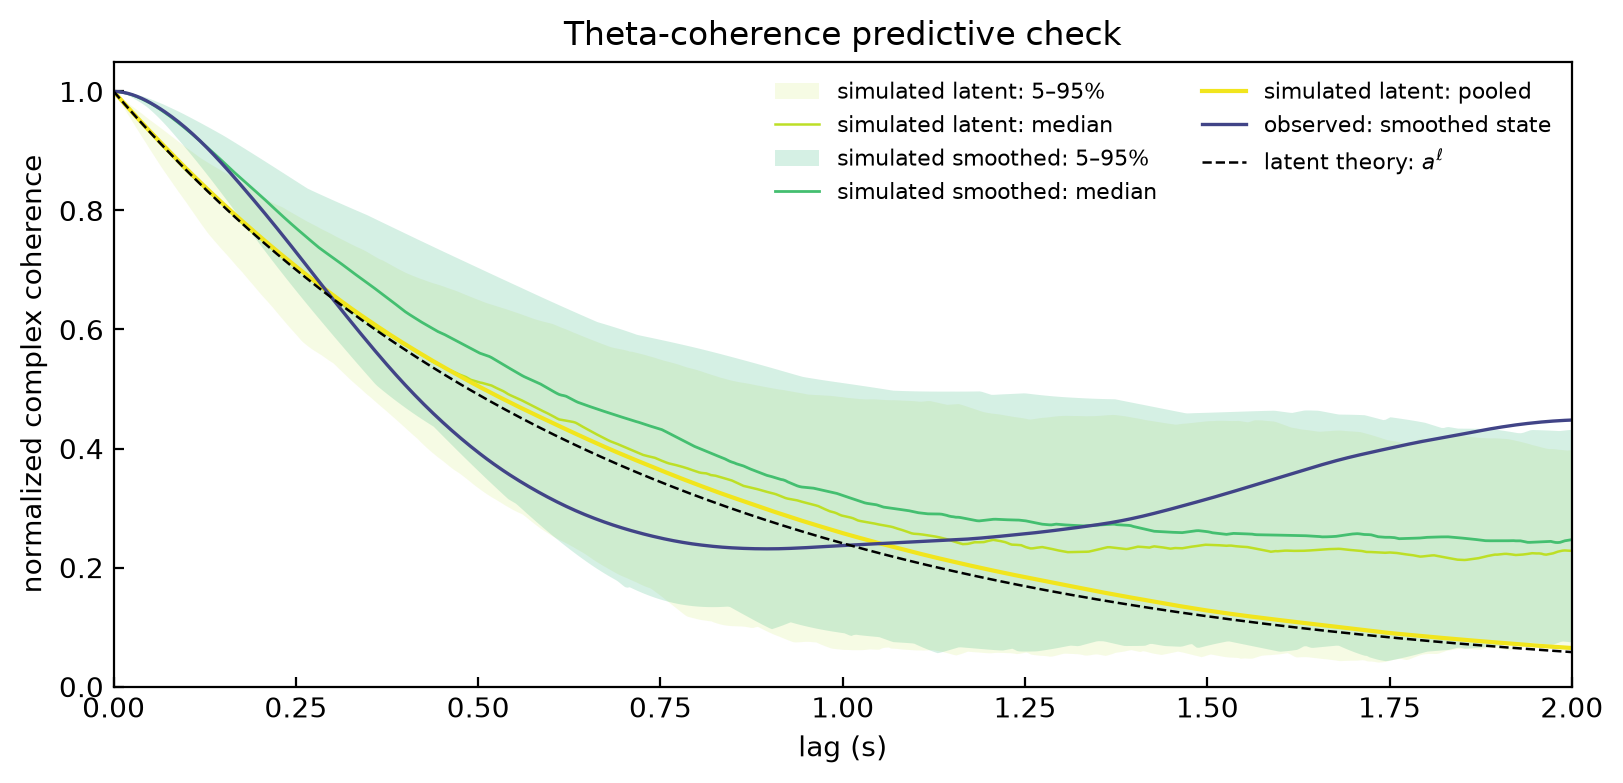

In [34]:
coherence_lo, coherence_median, coherence_hi = np.percentile(
    simulated_coherences, [5, 50, 95], axis=0
)
latent_coherence_lo, latent_coherence_median, latent_coherence_hi = np.percentile(
    simulated_latent_coherences, [5, 50, 95], axis=0
)
theoretical_coherence = theta_damping**coherence_lags

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.fill_between(
    coherence_times,
    latent_coherence_lo,
    latent_coherence_hi,
    color=cmap(0.9),
    alpha=0.12,
    lw=0,
    label='simulated latent: 5–95%',
)
ax.plot(
    coherence_times,
    latent_coherence_median,
    color=cmap(0.9),
    lw=0.9,
    label='simulated latent: median',
)
ax.fill_between(
    coherence_times,
    coherence_lo,
    coherence_hi,
    color=cmap(0.65),
    alpha=0.2,
    lw=0,
    label='simulated smoothed: 5–95%',
)
ax.plot(
    coherence_times,
    coherence_median,
    color=cmap(0.7),
    lw=1,
    label='simulated smoothed: median',
)
ax.plot(
    coherence_times,
    pooled_latent_coherence,
    color=cmap(0.98),
    lw=1.5,
    label='simulated latent: pooled',
)
ax.plot(
    coherence_times,
    observed_coherence,
    color=cmap(0.2),
    lw=1.2,
    label='observed: smoothed state',
)
ax.plot(
    coherence_times,
    theoretical_coherence,
    'k--',
    lw=0.9,
    label=r'latent theory: $a^\ell$',
)
ax.set(
    xlabel='lag (s)',
    ylabel='normalized complex coherence',
    title='Theta-coherence predictive check',
    xlim=(coherence_times[0], coherence_times[-1]),
    ylim=(0, 1.05),
)
ax.tick_params(direction='in')
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()

## Interpretation

The pooled latent simulations provide an internal check on the fitted model: their amplitude and coherence should follow the Rayleigh and $a^\ell$ predictions, respectively. The smoothed simulations are the appropriate comparison with the EEG because both pass through the same inference procedure. The observed smoothed theta amplitude is markedly more persistent than the fitted linear model predicts: its coefficient of variation is 0.172 and its low-amplitude occupancy is 0.004, both below all 100 simulated values. Persistence of the observed complex coherence beyond the smoothed-simulation envelope would provide an additional signature of mismatch. These results support the proposed limit-cycle interpretation, but the checks diagnose model inadequacy rather than constitute a formal comparison with a fitted stochastic limit-cycle model.